# Lecture 27 · Build a Genome Graph with Neo4j

**Data Bases and Data Wrangling Series · NoSQL Databases for Bioinformatics**

In this workshop we turn a table of *"which genome carries which gene function"* into a **graph database** and then ask two real biological questions with a few lines of **Cypher** (Neo4j's query language).

> 💡 **How to use this notebook**
> * Run the cells **from top to bottom** (`Shift + Enter` runs one cell). Later cells depend on earlier ones.
> * Every step has three parts: **why** we do it (text), **how** (the code, with comments), and **what to notice** (the output).
> * 🧪 *Your turn* boxes are small exercises. A hidden solution is in a folded **"Show solution"** block; try first!
> * Stuck, or the graph looks wrong? Jump to [Appendix C](#appendix-c--troubleshooting) at the end.

## Learning objectives

At the end of this session, you will be able to:

1. **Model** genomic data as a graph (nodes, relationships, properties)
2. **Build** a genomic graph database with Neo4j (constraints, bulk import, sanity checks)
3. Obtain **biological insights** via graph querying
   * identify **similar genomes** based on shared KO annotations
   * infer **evolutionary patterns of KOs** across a phylogenetic structure

### Roadmap

| Step | What we do | Notebook section |
|:---:|---|---|
| 0 | Connect to the local Neo4j database | [Section 0](#0--setup-and-connection) |
| 1 | Understand the biology and the data | [Section 1](#1--the-biology-and-the-data) |
| 2 | **Model** the data as a graph | [Section 2](#2--model-from-tables-to-a-graph) |
| 3 | Warm-up with a tiny hand-made graph | [Section 3](#3--warm-up-build-a-tiny-graph-by-hand) |
| 4 | **Import** the real data | [Section 4](#4--import-build-the-real-graph) |
| 5 | **Explore** the graph | [Section 5](#5--explore-get-to-know-your-graph) |
| 6 | **Query 1**: which genomes are similar? | [Section 6](#6--insight-1-which-genomes-are-similar) |
| 7 | **Query 2**: how did KOs evolve across the tree? | [Section 7](#7--insight-2-how-did-kos-evolve-across-the-tree) |
| 8 | Wrap-up and next steps | [Section 8](#8--wrap-up) |

---
## 0 · Setup and connection

### 0.1 What do you need running?

Everything runs **on your own laptop**, no internet or cloud account is needed. In a terminal, from the `docker/` folder of this repository:

```bash
docker compose up -d      # start MongoDB + Neo4j in the background
docker compose ps         # both services should say "healthy"
```

(The full install guide is in [`SETUP.md`](../SETUP.md).) You can also open the **Neo4j Browser**, a web UI for the database, at <http://localhost:7474>
(user `neo4j`, password `workshop_neo4j`). It is handy for drawing graphs of your query results.

### 0.2 How does Python talk to Neo4j?

```
 this notebook  ──(Bolt protocol, port 7687)──▶  Neo4j server (Docker container)
 neo4j Python driver                              stores the graph, runs Cypher
```

* The **driver** (`neo4j` package) opens network connections to the server and sends Cypher text.
* The connection address `bolt://localhost:7687` means *"this computer, port 7687"*; Docker forwards that port into the container.
* A `driver` object is **expensive to create but cheap to reuse**: create it **once** per notebook.

In [1]:
# --- imports --------------------------------------------------------------
import csv                       # read the CSV files line by line
import os                        # read optional settings from environment variables
import time                      # measure how long things take
from pathlib import Path         # file paths that work on Windows, macOS and Linux

import matplotlib.pyplot as plt  # plots
import pandas as pd              # tables (DataFrames)
from neo4j import GraphDatabase, Result      # the official Neo4j driver
from neo4j_viz.neo4j import from_neo4j       # turns query results into an interactive graph picture

pd.set_option("display.max_colwidth", 70)    # keep long names readable in tables
pd.set_option("display.width", 160)

# --- connection settings ----------------------------------------------------------
# These defaults match docker/docker-compose.yml. Only change them if you changed the compose file
# (for example MONGO/NEO4J ports) by setting environment variables before starting Jupyter.
NEO4J_PORT = os.getenv("NEO4J_BOLT_PORT", "7687")
NEO4J_URI  = os.getenv("NEO4J_URI", f"bolt://localhost:{NEO4J_PORT}")
NEO4J_USER = os.getenv("NEO4J_USERNAME", "neo4j")
NEO4J_PASS = os.getenv("NEO4J_PASSWORD", "workshop_neo4j")

# --- the driver: create ONCE, reuse everywhere ----------------------------------
driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASS))
driver.verify_connectivity()     # raises a clear error if the container is not running / wrong password
print("Connected to:", driver.get_server_info().agent, "at", NEO4J_URI)

Connected to: Neo4j/5.26.32 at bolt://localhost:7687


### 0.3 Three little helper functions

Writing the same boilerplate over and over would hide the interesting part (the Cypher). So we wrap it once:

| helper | what it does | typical use |
|---|---|---|
| `run_cypher(query, **params)` | runs a query and returns a **pandas table** | `MATCH ... RETURN ...` |
| `run_write(query, **params)` | runs a query and prints **what changed** (nodes/relationships created, ...) | `CREATE`, `MERGE`, `SET`, `DELETE` |
| `show_graph(query, **params)` | runs a query that returns **nodes / relationships / paths** and draws an interactive graph | exploring neighbourhoods |

**Query parameters.** Notice the `**params`. Instead of gluing values into the query text with f-strings, we write `$name` in Cypher and pass `name=...` from Python:

```python
run_cypher("MATCH (g:Genome {genome_id: $gid}) RETURN g.name", gid="eco")
```

This is safer (no injection of unexpected text), clearer, and lets Neo4j **re-use the query plan**. Always prefer parameters over f-strings for *values*.

In [2]:
def run_cypher(query, **params):
    """Run a (read) query and return the result as a pandas DataFrame."""
    return driver.execute_query(query, parameters_=params, database_="neo4j",
                                result_transformer_=Result.to_df)


def run_write(query, quiet=False, **params):
    """Run a query that changes the graph and print what changed (nothing is returned)."""
    t0 = time.time()
    summary = driver.execute_query(query, parameters_=params, database_="neo4j").summary
    c = summary.counters
    changes = {k: v for k, v in {
        "nodes created": c.nodes_created, "nodes deleted": c.nodes_deleted,
        "relationships created": c.relationships_created, "relationships deleted": c.relationships_deleted,
        "properties set": c.properties_set, "labels added": c.labels_added,
        "constraints added": c.constraints_added,
    }.items() if v}
    if not quiet:
        print(f"{time.time() - t0:5.2f}s ", changes or "(no changes)")


def show_graph(query, caption="name", height="450px", **params):
    """Run a query that RETURNs nodes / relationships / paths and draw them.
    `caption` = the node property used as the text label of every node."""
    graph = driver.execute_query(query, parameters_=params, database_="neo4j",
                                 result_transformer_=Result.graph)
    return from_neo4j(graph, node_caption=caption).render(height=height)


# a quick self-test: how many nodes does the database hold right now?
run_cypher("MATCH (n) RETURN count(n) AS nodes_in_database")

,nodes_in_database
0,0


> **What to notice:** the database is probably empty (`0`) right now. If you ran this notebook before, it may still contain a graph: that is fine, we will wipe and rebuild it in [Section 4](#4--import-build-the-real-graph).

---
## 1 · The biology and the data

### 1.1 Genomes, genes, and KOs

* A **genome** is the complete DNA of an organism. We predict its **genes**, and for each gene we ask *"what does this protein do?"*
* **KEGG Orthology (KO)** is a catalogue of gene *functions*. A KO is like a **part number** in a parts catalogue: `K04077` = *"chaperonin GroEL"*, `K02703` = *"photosystem II D1 protein (psbA)"*.
  If a gene of a genome is labelled `K04077`, that genome **can do** that function.
* So every genome can be summarised by the **set of KOs it carries**, a *functional fingerprint*.

```
 Genome (E. coli)                      KO fingerprint
 ┌─────────────────────┐
 │ gene 1  → K08278    │               { K08278, K12524, K00872, K01733, ... }   ← about 3,000 KOs
 │ gene 2  → K12524    │
 │ gene 3  → K00872    │
 └─────────────────────┘
```

### 1.2 The phylogenetic structure

Life is a **tree**: species group into genera, genera into families, ... up to domains (Bacteria / Archaea).
Closely related organisms share a recent common ancestor and therefore tend to share genes.

> ⚠️ **A note on "phylogeny".** We use the **NCBI taxonomy** (domain › phylum › class › order › family › genus › species) as our tree.
> It is not a perfect evolutionary tree (rigorous studies build trees from sequence alignments), but it follows evolution closely enough
> for learning, and it is a *real* hierarchy that a graph database handles beautifully.

### 1.3 Our two questions

| # | Question | Graph idea |
|:-:|---|---|
| **Q1** | *Which genomes have similar functional repertoires?* | two genomes are similar if they are connected to many of the **same KO nodes** (`Genome → KO ← Genome`) |
| **Q2** | *How are KOs distributed over the tree of life? Which are ancestral, which are clade-specific, which are patchy?* | walk **up the tree** from the genomes that carry a KO and see where they meet |

### 1.4 The dataset

65 reference genomes (58 bacteria + 7 archaea; the famous model organisms, pathogens, endosymbionts, cyanobacteria ...) annotated with KEGG KOs.
The CSV files are in `data/neo4j/` and were prepared by [`data/prepare/build_genome_graph_data.py`](../data/prepare/build_genome_graph_data.py)
(sources: KEGG and NCBI Taxonomy; see [`data/README.md`](../data/README.md)). You do **not** need internet access to use them.

In [3]:
# Where are the data files? (the notebook lives in 4-neo4j-workshop/, the data in ../data/neo4j/)
DATA_DIR = Path("../data/neo4j")
assert DATA_DIR.exists(), f"Cannot find {DATA_DIR.resolve()}. Start Jupyter from inside the 4-neo4j-workshop folder."

files = sorted(DATA_DIR.glob("*.csv"))
for f in files:
    n_rows = sum(1 for _ in open(f)) - 1          # minus the header line
    print(f"{f.name:<16} {n_rows:>7,} rows   {f.stat().st_size / 1024:>8,.0f} KB")

genome_ko.csv     90,445 rows      1,148 KB
genomes.csv           65 rows          5 KB
ko_pathway.csv     7,579 rows        118 KB
kos.csv            8,994 rows        537 KB
pathways.csv         356 rows         13 KB
taxa.csv             270 rows          8 KB
taxon_tree.csv       269 rows          3 KB


Let's look at the first rows of each file with pandas. Read them as a *data detective*: **what is one row?** **what identifies it?** **which column points to another file?**

In [4]:
genomes   = pd.read_csv(DATA_DIR / "genomes.csv")
kos       = pd.read_csv(DATA_DIR / "kos.csv").fillna("")
genome_ko = pd.read_csv(DATA_DIR / "genome_ko.csv")
taxa      = pd.read_csv(DATA_DIR / "taxa.csv")
tree      = pd.read_csv(DATA_DIR / "taxon_tree.csv")
pathways  = pd.read_csv(DATA_DIR / "pathways.csv")
ko_path   = pd.read_csv(DATA_DIR / "ko_pathway.csv")

print("genomes.csv  - one row per GENOME");           display(genomes.head(3))
print("kos.csv      - one row per KO (gene function)"); display(kos.head(3))
print("genome_ko.csv - one row per (genome, KO) PAIR, 'copies' = how many genes carry that KO"); display(genome_ko.head(3))
print("taxa.csv + taxon_tree.csv - the tree: one row per taxonomic group, and one row per child -> parent link")
display(taxa.head(4)); display(tree.head(3))

genomes.csv  - one row per GENOME


,genome_id,name,kegg_id,taxid,species_taxid,assembly,n_protein_genes,n_kos
0,aae,Aquifex aeolicus,T00013,224324,63363,GCA_000008625.1,1553,964
1,amu,Akkermansia muciniphila,T00736,349741,239935,GCA_000020225.1,2138,970
2,ana,Nostoc sp. PCC 7120,T00069,103690,103690,GCA_000009705.1,6132,1566


kos.csv      - one row per KO (gene function)


,ko_id,symbol,definition
0,K00002,"AKR1A1, adh",alcohol dehydrogenase (NADP+) [EC:1.1.1.2]
1,K00003,hom,homoserine dehydrogenase [EC:1.1.1.3]
2,K00004,"BDH, butB","(R,R)-butanediol dehydrogenase / meso-butanediol dehydrogenase / d..."


genome_ko.csv - one row per (genome, KO) PAIR, 'copies' = how many genes carry that KO


,genome_id,ko_id,copies
0,aae,K00003,1
1,aae,K00012,1
2,aae,K00013,1


taxa.csv + taxon_tree.csv - the tree: one row per taxonomic group, and one row per child -> parent link


,taxid,name,rank,rank_level
0,131567,cellular organisms,root,0
1,2157,Archaea,domain,1
2,2,Bacteria,domain,1
3,201174,Actinomycetota,phylum,2


,child_taxid,parent_taxid
0,2157,131567
1,2,131567
2,201174,2


### 1.5 Data dictionary

| file | one row is... | key columns | points to |
|---|---|---|---|
| `genomes.csv` | a genome | `genome_id` (KEGG organism code, e.g. `eco`) | `species_taxid` → `taxa.csv` |
| `kos.csv` | a KEGG Orthology group | `ko_id` (e.g. `K04077`) | |
| `genome_ko.csv` | "genome *G* carries KO *K*" | `genome_id`, `ko_id` + `copies` | → `genomes.csv`, → `kos.csv` |
| `taxa.csv` | a taxonomic group | `taxid`, `rank`, `rank_level` (0 = root … 7 = species) | |
| `taxon_tree.csv` | "group *C* sits inside group *P*" | `child_taxid`, `parent_taxid` | → `taxa.csv` (twice) |
| `pathways.csv` | a KEGG pathway map | `pathway_id` (e.g. `map00010`) | |
| `ko_pathway.csv` | "KO *K* takes part in pathway *P*" | `ko_id`, `pathway_id` | → `kos.csv`, → `pathways.csv` |

> 🔎 **Look at the shape of this data.** `genome_ko.csv`, `taxon_tree.csv` and `ko_pathway.csv` are all *lists of connections between two things*.
> In a relational database they are "link tables" that you must JOIN again and again. In a graph database a connection is a **first-class citizen**:
> it is stored directly and can be followed in constant time. That is the whole point of today's lecture.

### 1.6 A first taste: why not just use SQL?

*"Which genomes share the most KOs with each other?"* in SQL needs a **self-join** of the biggest table:

```sql
SELECT a.genome_id, b.genome_id, COUNT(*) AS shared_kos
FROM   genome_ko a
JOIN   genome_ko b ON a.ko_id = b.ko_id AND a.genome_id < b.genome_id   -- pair up rows with the same KO
GROUP  BY a.genome_id, b.genome_id;
```

And *"all ancestors of a genome"* needs a **recursive** query (`WITH RECURSIVE ...`) because the depth of the tree is not known in advance.
You *can* do both in SQL; we will see the same ideas expressed as simple **patterns** in Cypher.

---
## 2 · Model: from tables to a graph

Graph modelling is easiest on a **whiteboard**. Follow this recipe:

| Step | Ask yourself | Rule of thumb |
|:---:|---|---|
| 1 | What are the **things** in my data? | nouns → **nodes** (each kind gets a **label**) |
| 2 | How are the things **connected**? | verbs → **relationships** (each has a **type**, a **direction** and can have properties) |
| 3 | What do I know **about** each thing / connection? | attributes → **properties** (key–value pairs) |
| 4 | Which **questions** will I ask? | If a question follows a link often, that link should be a relationship |

### 2.1 Applying the recipe

**Nodes (things)**

| Label | Represents | Identified by | Example properties |
|---|---|---|---|
| `Genome` | one sequenced genome | `genome_id` | `name`, `assembly`, `n_protein_genes` |
| `KO` | one gene function | `ko_id` | `name`, `symbol`, `definition` |
| `Taxon` | one group in the tree of life | `taxid` | `name`, `rank`, `rank_level` |
| `Pathway` | a metabolic / signalling map | `pathway_id` | `name` |

**Relationships (connections)**

| Pattern | Meaning | Properties |
|---|---|---|
| `(:Genome)-[:CONTAINS_KO]->(:KO)` | the genome has at least one gene with this function | `copies` |
| `(:Genome)-[:CLASSIFIED_AS]->(:Taxon)` | the species the genome belongs to | |
| `(:Taxon)-[:CHILD_OF]->(:Taxon)` | the tree: *genus* is a child of *family*, ... | |
| `(:KO)-[:IN_PATHWAY]->(:Pathway)` | the function takes part in the pathway | |

```mermaid
graph LR
    G(["Genome<br/>genome_id, name"]) -- "CONTAINS_KO {copies}" --> K(["KO<br/>ko_id, symbol, definition"])
    G -- CLASSIFIED_AS --> T(["Taxon<br/>taxid, name, rank"])
    T -- "CHILD_OF (the tree)" --> T
    K -- IN_PATHWAY --> P(["Pathway<br/>pathway_id, name"])
```

### 2.2 Design decisions: the "why" behind the model

These choices matter more than the syntax. Discuss them with your neighbour:

1. **Why is a KO a *node* and not a list stored inside the Genome node?**
   If `Genome.kos = ["K00001", ...]` were a property, finding *"all genomes that have K04077"* would require scanning **every** genome and searching its list.
   As a node, `K04077` knows its genomes directly, and the pattern `Genome → KO ← Genome` (Q1) becomes a two-step walk.
2. **Why is `copies` stored on the relationship?**
   *Copy number* is not a property of the genome alone, nor of the KO alone: it describes the **pair**. Properties that describe a connection belong on the connection.
3. **Why are taxa nodes connected by `CHILD_OF` rather than a column "phylum" in `Genome`?**
   With a column you can only ask about the ranks you foresaw. With a *tree of nodes* you can ask about **any** clade at **any** depth, with one pattern (`-[:CHILD_OF*]->`). Adding a rank later changes no query.
4. **Why does a Genome link only to its *species* and not to every ancestor?**
   Redundant links would have to be kept in sync. Ancestors are always one traversal away, store each fact **once**.
5. **Does the arrow direction matter?**
   Direction is just how the relationship is *stored* (`child → parent`, `genome → KO`). You can traverse it either way (`-->`, `<--`) or ignore it (`--`). Pick a direction that reads like a sentence: *"Genome CONTAINS_KO KO"*.
6. **Why a separate `Pathway` layer?**
   It lets us *interpret* results: from "these 36 KOs were lost" to "these are *steroid-degradation* functions". It is optional for Q1 and Q2.

---
## 3 · Warm-up: build a tiny graph by hand

Before importing 98,000 relationships, let's create a graph so small that we can verify every answer by eye:
**4 genomes** and **5 KOs**.

| KO | function | who has it? |
|---|---|---|
| `K04077` groEL | chaperone, essential protein folding | everyone |
| `K03043` rpoB | RNA polymerase subunit | everyone |
| `K02406` fliC | flagellin → swimming with a flagellum | *E. coli*, *B. subtilis* |
| `K07699` spo0A | master regulator of **spore** formation | *B. subtilis* only |
| `K02703` psbA | photosystem II → **photosynthesis** | *Synechocystis* only |

### 3.1 Cypher in 60 seconds

```
(g:Genome {genome_id: 'eco'})            a NODE      · variable g · label Genome · property genome_id
-[:CONTAINS_KO {copies: 1}]->            a RELATIONSHIP · type CONTAINS_KO · a property · direction →
```

| keyword | meaning |
|---|---|
| `CREATE` | always make a new node / relationship (running it twice makes **two**) |
| `MERGE`  | *get or create*: make it only if it does not exist yet. Safe to re-run ✅ (we use it for everything) |
| `MATCH`  | find existing nodes / patterns |
| `SET`    | add or change properties |
| `RETURN` | give the results back to Python |

The three **MERGE** statements below say: *"make sure this genome exists"*, *"make sure this KO exists"*, *"make sure this link exists"*.

In [5]:
toy_graph = """
// 1) the genomes  (MERGE = create only if missing)
MERGE (eco:Genome {genome_id: 'eco'}) SET eco.name = 'Escherichia coli K-12'
MERGE (bsu:Genome {genome_id: 'bsu'}) SET bsu.name = 'Bacillus subtilis 168'
MERGE (syn:Genome {genome_id: 'syn'}) SET syn.name = 'Synechocystis sp. PCC 6803'
MERGE (mge:Genome {genome_id: 'mge'}) SET mge.name = 'Mycoplasma genitalium'

// 2) the KOs
MERGE (groel :KO {ko_id: 'K04077'}) SET groel.name  = 'groEL'
MERGE (rpob  :KO {ko_id: 'K03043'}) SET rpob.name   = 'rpoB'
MERGE (flic  :KO {ko_id: 'K02406'}) SET flic.name   = 'fliC'
MERGE (spo0a :KO {ko_id: 'K07699'}) SET spo0a.name  = 'spo0A'
MERGE (psba  :KO {ko_id: 'K02703'}) SET psba.name   = 'psbA'

// 3) the relationships: who carries what?
MERGE (eco)-[:CONTAINS_KO]->(groel)  MERGE (eco)-[:CONTAINS_KO]->(rpob)  MERGE (eco)-[:CONTAINS_KO]->(flic)
MERGE (bsu)-[:CONTAINS_KO]->(groel)  MERGE (bsu)-[:CONTAINS_KO]->(rpob)  MERGE (bsu)-[:CONTAINS_KO]->(flic)  MERGE (bsu)-[:CONTAINS_KO]->(spo0a)
MERGE (syn)-[:CONTAINS_KO]->(groel)  MERGE (syn)-[:CONTAINS_KO]->(rpob)  MERGE (syn)-[:CONTAINS_KO]->(psba)
MERGE (mge)-[:CONTAINS_KO]->(groel)  MERGE (mge)-[:CONTAINS_KO]->(rpob)
"""
run_write(toy_graph)

 0.34s  {'nodes created': 9, 'relationships created': 12, 'properties set': 18, 'labels added': 9}


Now *look* at it. `show_graph` draws every node and relationship that the query returns; you can drag nodes around, zoom with the mouse wheel, and hover or click for details.

In [6]:
show_graph("MATCH (g:Genome)-[r:CONTAINS_KO]->(k:KO) RETURN g, r, k", height="420px")

[Interactive graph: run this cell to draw it. The widget is not stored in the notebook file.]

**What to notice:** `groEL` and `rpoB` are connected to *all* genomes (they are *universal*), while `spo0A` and `psbA` each connect to a single genome (they are *distinctive*).
Which two genomes look most alike?

### 3.2 Our first similarity query

In words: *"start at E. coli, walk to each KO it has, then walk to every other genome that also has that KO, and count how many KOs we passed through"*.
In Cypher the sentence is drawn as a picture of the pattern:

```
(e:Genome {genome_id:'eco'}) -[:CONTAINS_KO]-> (k:KO) <-[:CONTAINS_KO]- (other:Genome)
        you are here               a KO that e has           another genome that has the same KO
```

In [7]:
run_cypher("""
MATCH (e:Genome {genome_id: 'eco'})-[:CONTAINS_KO]->(k:KO)<-[:CONTAINS_KO]-(other:Genome)
WHERE other <> e                                   // don't compare E. coli with itself
RETURN other.name              AS genome,
       count(k)                AS shared_kos,      // count() groups by the other returned columns (genome)
       collect(k.name)         AS which_kos        // collect() gathers values into a list
ORDER BY shared_kos DESC
""")

,genome,shared_kos,which_kos
0,Bacillus subtilis 168,3,"[rpoB, groEL, fliC]"
1,Mycoplasma genitalium,2,"[rpoB, groEL]"
2,Synechocystis sp. PCC 6803,2,"[rpoB, groEL]"


**What to notice:**
* *B. subtilis* shares **3** KOs with *E. coli* (groEL, rpoB, fliC), the other two share only the 2 universal KOs.
* There is **no `GROUP BY`** in Cypher: as soon as you use an aggregation (`count`, `collect`, ...), every *non*-aggregated column in `RETURN` automatically becomes the grouping key.

> ⚠️ **Raw counts have a catch.** *M. genitalium* has only 2 KOs in our toy graph and *both* are shared with E. coli, so it is "100% contained in E. coli", yet it is not a close relative, it is just small.
> We will fix this with a normalised score (the **Jaccard index**) in [Section 6](#6--insight-1-which-genomes-are-similar).

### 3.3 Clean up

The real dataset uses the same labels, so we remove the toy graph before importing. `DETACH DELETE` removes nodes *and* the relationships attached to them (plain `DELETE` refuses to delete a node that still has relationships).

In [8]:
run_write("MATCH (n) DETACH DELETE n")          # careful: this wipes EVERYTHING in the database
run_cypher("MATCH (n) RETURN count(n) AS nodes_left")

 0.01s  {'nodes deleted': 9, 'relationships deleted': 12}


,nodes_left
0,0


> 🧪 **Your turn (optional, 3 min).** Add a fifth genome of your choice to the toy graph (use `MERGE`), give it `groEL` and `fliC`, and re-run the similarity query. Which genome is it most similar to?
> *Hint:* first re-run the toy-graph cell (we just deleted it), then add your own `MERGE` statements in a new cell. Don't forget to clean up again before Section 4!

---
## 4 · Import: build the real graph

### 4.1 The plan

```
 CSV files ──(Python reads rows)──▶ batches of 5,000 rows ──(UNWIND)──▶ Cypher MERGE ──▶ Neo4j
```

**Order matters.** A relationship needs both of its end nodes to exist, so we import in two waves:

1. **Wave 1 · nodes:** `Genome`, `KO`, `Taxon`, `Pathway`
2. **Wave 2 · relationships:** `CONTAINS_KO`, `CLASSIFIED_AS`, `CHILD_OF`, `IN_PATHWAY`

### 4.2 Constraints first: uniqueness *and* speed

A **uniqueness constraint** says *"no two `Genome` nodes may have the same `genome_id`"*. Two benefits:

* **Integrity:** a typo or a repeated import cannot silently create duplicates.
* **Speed:** Neo4j automatically builds an **index** behind each constraint. When wave 2 says
  `MATCH (g:Genome {genome_id: 'eco'})` it jumps straight to that node instead of scanning all genomes.
  *Without these indexes, wave 2 (90,000 look-ups × 2) would take minutes instead of seconds.*

First we empty the database, so that this cell can be re-run at any time to start over from scratch.

In [9]:
run_write("MATCH (n) DETACH DELETE n")        # start from an empty database (safe to re-run)

constraints = [
    "CREATE CONSTRAINT genome_id  IF NOT EXISTS FOR (g:Genome)  REQUIRE g.genome_id  IS UNIQUE",
    "CREATE CONSTRAINT ko_id      IF NOT EXISTS FOR (k:KO)      REQUIRE k.ko_id      IS UNIQUE",
    "CREATE CONSTRAINT taxon_id   IF NOT EXISTS FOR (t:Taxon)   REQUIRE t.taxid      IS UNIQUE",
    "CREATE CONSTRAINT pathway_id IF NOT EXISTS FOR (p:Pathway) REQUIRE p.pathway_id IS UNIQUE",
]
for statement in constraints:       # "IF NOT EXISTS" makes each statement safe to repeat
    run_write(statement)

run_cypher("SHOW CONSTRAINTS YIELD name, type, labelsOrTypes, properties")

 0.00s  (no changes)
 0.03s  {'constraints added': 1}


 0.02s  {'constraints added': 1}
 0.01s  {'constraints added': 1}
 0.02s  {'constraints added': 1}


,name,type,labelsOrTypes,properties
0,genome_id,UNIQUENESS,[Genome],[genome_id]
1,ko_id,UNIQUENESS,[KO],[ko_id]
2,pathway_id,UNIQUENESS,[Pathway],[pathway_id]
3,taxon_id,UNIQUENESS,[Taxon],[taxid]


### 4.3 Reading the CSV files and sending them in batches

Two small helpers:

* `read_csv_rows(file)` reads a CSV into a **list of dictionaries**, one per row, e.g. `{'genome_id': 'eco', 'name': 'Escherichia coli K-12 MG1655', ...}`.
  Beware: `csv` returns **everything as text**. Numbers must be converted (`int(...)`) in Python, otherwise Neo4j would store `"4288"` (a string) and `n_protein_genes > 4000` would not work as expected.
* `load_in_batches(query, rows)` sends the rows to Neo4j **5,000 at a time**.

**Why batches?** One row per query would need 90,000 network round-trips (slow). All rows in one transaction would need a lot of memory (risky).
A few thousand rows per transaction is the usual sweet spot.

**The `UNWIND $rows AS row` pattern** is the workhorse of Neo4j imports: `UNWIND` turns a *list* parameter into *one result row per item*, and the rest of the query runs **once per row**, like a `for row in rows:` loop written in Cypher.

In [10]:
def read_csv_rows(filename):
    """Read a CSV file from DATA_DIR into a list of dicts (all values are text!)."""
    with open(DATA_DIR / filename, newline="") as fh:
        return list(csv.DictReader(fh))


def load_in_batches(query, rows, batch_size=5000, label=""):
    """Run `query` once per batch of rows. The query must start with `UNWIND $rows AS row`."""
    t0, created_nodes, created_rels = time.time(), 0, 0
    for start in range(0, len(rows), batch_size):
        summary = driver.execute_query(query, parameters_={"rows": rows[start:start + batch_size]},
                                       database_="neo4j").summary
        created_nodes += summary.counters.nodes_created
        created_rels += summary.counters.relationships_created
    print(f"{label:<28} {len(rows):>7,} rows in {time.time() - t0:5.1f}s   "
          f"-> {created_nodes:>6,} nodes, {created_rels:>7,} relationships created")

### 4.4 Wave 1: the nodes

Read the Cypher like a sentence: *"for each row, **MERGE** (find or create) a `Genome` node identified by its `genome_id`, then **SET** the other properties"*.
We put only the **identifying** property inside `MERGE {...}` and everything else in `SET`: that is the safe pattern, because `MERGE` looks for a node matching *all* the properties inside the braces.

In [11]:
# ---- convert the text columns that are really numbers --------------------------------
genome_rows = [dict(r, taxid=int(r["taxid"]), species_taxid=int(r["species_taxid"]),
                    n_protein_genes=int(r["n_protein_genes"])) for r in read_csv_rows("genomes.csv")]

ko_rows = []
for r in read_csv_rows("kos.csv"):
    # KO symbols look like "RP-L3, MRPL3, rplC". For a short display name keep the first one
    # (or fall back to the KO id when a KO has no symbol at all).
    ko_rows.append({**r, "name": r["symbol"].split(",")[0].strip() or r["ko_id"]})

taxon_rows    = [dict(r, taxid=int(r["taxid"]), rank_level=int(r["rank_level"])) for r in read_csv_rows("taxa.csv")]
pathway_rows  = read_csv_rows("pathways.csv")

# ---- the four node-loading queries ------------------------------------------------------
load_in_batches("""
    UNWIND $rows AS row
    MERGE (g:Genome {genome_id: row.genome_id})
    SET g.name = row.name, g.kegg_id = row.kegg_id, g.taxid = row.taxid,
        g.assembly = row.assembly, g.n_protein_genes = row.n_protein_genes
""", genome_rows, label="Genome nodes")

load_in_batches("""
    UNWIND $rows AS row
    MERGE (k:KO {ko_id: row.ko_id})
    SET k.name = row.name, k.symbol = row.symbol, k.definition = row.definition
""", ko_rows, label="KO nodes")

load_in_batches("""
    UNWIND $rows AS row
    MERGE (t:Taxon {taxid: row.taxid})
    SET t.name = row.name, t.rank = row.rank, t.rank_level = row.rank_level
""", taxon_rows, label="Taxon nodes")

load_in_batches("""
    UNWIND $rows AS row
    MERGE (p:Pathway {pathway_id: row.pathway_id})
    SET p.name = row.name
""", pathway_rows, label="Pathway nodes")

Genome nodes                      65 rows in   0.1s   ->     65 nodes,       0 relationships created


KO nodes                       8,994 rows in   0.6s   ->  8,994 nodes,       0 relationships created
Taxon nodes                      270 rows in   0.0s   ->    270 nodes,       0 relationships created
Pathway nodes                    356 rows in   0.0s   ->    356 nodes,       0 relationships created


### 4.5 Wave 2: the relationships

Pattern: **find the two end nodes, then MERGE the relationship between them**.
Because the constraints created indexes, each `MATCH (g:Genome {genome_id: ...})` is an instant look-up.

`SET r.copies = row.copies` puts the **copy number on the relationship**, our design decision #2.

In [12]:
genome_ko_rows = [dict(r, copies=int(r["copies"])) for r in read_csv_rows("genome_ko.csv")]
tree_rows      = [dict(child=int(r["child_taxid"]), parent=int(r["parent_taxid"])) for r in read_csv_rows("taxon_tree.csv")]
ko_path_rows   = read_csv_rows("ko_pathway.csv")

load_in_batches("""
    UNWIND $rows AS row
    MATCH (g:Genome {genome_id: row.genome_id})
    MATCH (k:KO     {ko_id:     row.ko_id})
    MERGE (g)-[r:CONTAINS_KO]->(k)
    SET r.copies = row.copies
""", genome_ko_rows, label="(Genome)-[CONTAINS_KO]->(KO)")

load_in_batches("""
    UNWIND $rows AS row
    MATCH (child:Taxon  {taxid: row.child})
    MATCH (parent:Taxon {taxid: row.parent})
    MERGE (child)-[:CHILD_OF]->(parent)
""", tree_rows, label="(Taxon)-[CHILD_OF]->(Taxon)")

load_in_batches("""
    UNWIND $rows AS row
    MATCH (g:Genome {genome_id: row.genome_id})
    MATCH (t:Taxon  {taxid: row.species_taxid})
    MERGE (g)-[:CLASSIFIED_AS]->(t)
""", genome_rows, label="(Genome)-[CLASSIFIED_AS]->(Taxon)")

load_in_batches("""
    UNWIND $rows AS row
    MATCH (k:KO      {ko_id:      row.ko_id})
    MATCH (p:Pathway {pathway_id: row.pathway_id})
    MERGE (k)-[:IN_PATHWAY]->(p)
""", ko_path_rows, label="(KO)-[IN_PATHWAY]->(Pathway)")

(Genome)-[CONTAINS_KO]->(KO)  90,445 rows in   2.5s   ->      0 nodes,  90,445 relationships created
(Taxon)-[CHILD_OF]->(Taxon)      269 rows in   0.0s   ->      0 nodes,     269 relationships created
(Genome)-[CLASSIFIED_AS]->(Taxon)      65 rows in   0.0s   ->      0 nodes,      65 relationships created


(KO)-[IN_PATHWAY]->(Pathway)   7,579 rows in   0.2s   ->      0 nodes,   7,579 relationships created


### 4.6 Never trust an import: verify it

A classic data-engineering rule: **compare what is in the database with what was in the files.** Any difference means a bug in the import.

In [13]:
expected = {
    "Genome": len(genome_rows), "KO": len(ko_rows), "Taxon": len(taxon_rows), "Pathway": len(pathway_rows),
    "CONTAINS_KO": len(genome_ko_rows), "CHILD_OF": len(tree_rows),
    "CLASSIFIED_AS": len(genome_rows), "IN_PATHWAY": len(ko_path_rows),
}
nodes = run_cypher("MATCH (n)    RETURN labels(n)[0] AS name, count(*) AS in_database")
rels  = run_cypher("MATCH ()-[r]->() RETURN type(r)     AS name, count(*) AS in_database")
check = pd.concat([nodes, rels]).set_index("name")
check["in_csv_files"] = pd.Series(expected)
check["OK?"] = (check["in_database"] == check["in_csv_files"]).map({True: "✅", False: "❌ MISMATCH"})
check

,in_database,in_csv_files,OK?
name,,,
KO,8994,8994,✅
Genome,65,65,✅
Taxon,270,270,✅
Pathway,356,356,✅
CONTAINS_KO,90445,90445,✅
CHILD_OF,269,269,✅
CLASSIFIED_AS,65,65,✅
IN_PATHWAY,7579,7579,✅


All ✅? Then the import is complete. Neo4j can also **draw its own schema**, built from the data you actually loaded. Compare it with our whiteboard model in Section 2.

In [14]:
show_graph("CALL db.schema.visualization()", height="380px")

[Interactive graph: run this cell to draw it. The widget is not stored in the notebook file.]

### 4.7 (Optional) The server-side alternative: `LOAD CSV`

Neo4j can also read CSV files **by itself**, with no Python in between. Our Docker setup mounts `data/neo4j/` as the server's *import folder*, so Cypher can read `file:///genomes.csv`.
Here is a **read-only preview** (it changes nothing in the graph):

In [15]:
try:
    display(run_cypher("""
        LOAD CSV WITH HEADERS FROM 'file:///genomes.csv' AS row      // one `row` per CSV line (all values are text)
        RETURN row.genome_id AS genome_id, row.name AS name, toInteger(row.n_protein_genes) AS n_protein_genes
        LIMIT 3
    """))
except Exception as err:      # e.g. you are connected to a server that cannot see our data folder
    print("LOAD CSV is not available in this setup (that is fine, Python import above is enough):\n", err)

,genome_id,name,n_protein_genes
0,aae,Aquifex aeolicus,1553
1,amu,Akkermansia muciniphila,2138
2,ana,Nostoc sp. PCC 7120,6132


The complete Cypher-only equivalent of our node import would look like this *(shown, not executed)*:

```cypher
CREATE CONSTRAINT genome_id IF NOT EXISTS FOR (g:Genome) REQUIRE g.genome_id IS UNIQUE;

LOAD CSV WITH HEADERS FROM 'file:///genomes.csv' AS row
CALL (row) {                                   // "CALL { }" = run the block in separate transactions
  MERGE (g:Genome {genome_id: row.genome_id})
  SET g.name = row.name, g.n_protein_genes = toInteger(row.n_protein_genes)
} IN TRANSACTIONS OF 1000 ROWS;
```

| | Python + `UNWIND` (what we did) | `LOAD CSV` |
|---|---|---|
| where does the file live? | anywhere Python can read | inside the server's import folder |
| type conversion | in Python (`int()`) | in Cypher (`toInteger()`) |
| works with remote / cloud servers | ✅ | ❌ (file must be on the server) |
| tooling around it | pandas, validation, logging | one self-contained Cypher script |

For **very** large imports (billions of rows) Neo4j also offers the offline `neo4j-admin database import` tool.

---
## 5 · Explore: get to know your graph

Before asking clever questions, look around. Good analysts always do.

### 5.1 How big is it?

In [16]:
print("Nodes per label")
display(nodes.rename(columns={"in_database": "nodes"}).set_index("name"))
print("Relationships per type")
display(rels.rename(columns={"in_database": "relationships"}).set_index("name"))

Nodes per label


,nodes
name,
KO,8994
Genome,65
Taxon,270
Pathway,356


Relationships per type


,relationships
name,
CONTAINS_KO,90445
CHILD_OF,269
CLASSIFIED_AS,65
IN_PATHWAY,7579


### 5.2 One genome in detail

`MATCH (g:Genome {genome_id: $gid})` means *"find the `Genome` node whose `genome_id` equals the parameter"*.
`COUNT { (g)-[:CONTAINS_KO]->() }` is a **counting sub-query**: *"how many `CONTAINS_KO` relationships leave this node?"* (also called the node's **degree**).

In [17]:
run_cypher("""
MATCH (g:Genome {genome_id: $gid})
RETURN g.genome_id AS id, g.name AS name, g.assembly AS assembly,
       g.n_protein_genes AS protein_genes,
       COUNT { (g)-[:CONTAINS_KO]->() } AS distinct_kos
""", gid="eco")

,id,name,assembly,protein_genes,distinct_kos
0,eco,Escherichia coli K-12 MG1655,GCF_000005845.2,4288,3047


*E. coli* has ~4,300 protein genes but only ~3,000 *distinct* KOs. Why the difference? Some genes have **no KO** (unknown function), and some KOs are carried by **several genes** (paralogs). That is exactly what the `copies` property on the relationship records:

In [18]:
run_cypher("""
MATCH (:Genome {genome_id: $gid})-[r:CONTAINS_KO]->(k:KO)
RETURN k.ko_id AS ko, k.name AS name, k.definition AS definition, r.copies AS copies
ORDER BY copies DESC
LIMIT 8
""", gid="eco")

,ko,name,definition,copies
0,K07497,K07497,putative transposase,12
1,K07481,K07481,"transposase, IS5 family",12
2,K07483,K07483,transposase,12
3,K03704,cspA,cold shock protein,9
4,K14228,tRNA-Leu,tRNA Leu,8
5,K14230,tRNA-Met,tRNA Met,8
6,K01985,5SrRNA,5S ribosomal RNA,8
7,K14219,tRNA-Arg,tRNA Arg,7


The champions are **transposases** (mobile genetic elements that copy themselves into new places), **tRNA / rRNA genes** (the ribosomal RNA operon is repeated ~7× in *E. coli*; cells that grow fast need lots of ribosomes) and stress proteins such as *cspA*. Copy number is biology too, which is why it deserves a place on the relationship.

### 5.3 One KO, and every genome that carries it

The same pattern read from the other side (the arrow is just a direction of storage; we can follow it **backwards**, `<-[:CONTAINS_KO]-`):

In [19]:
run_cypher("""
MATCH (k:KO {ko_id: $ko})<-[:CONTAINS_KO]-(g:Genome)
RETURN k.name AS ko, count(g) AS n_genomes, collect(g.genome_id) AS genome_ids
""", ko="K02703")       # psbA, photosystem II D1 protein

,ko,n_genomes,genome_ids
0,psbA,4,"[syn, syf, pma, ana]"


Only 4 genomes carry `K02703` (psbA, **photosynthesis**). Can you guess which clade they belong to? Keep that thought for [Section 7](#7--insight-2-how-did-kos-evolve-across-the-tree).

### 5.4 Pictures: neighbourhoods in the graph

Seeing the graph builds intuition. **Always add `LIMIT`** when drawing: a genome has ~3,000 neighbours and your browser would choke.

**(a)** *E. coli* and 25 of its KOs (colour = node label):

In [20]:
show_graph("""
MATCH p = (:Genome {genome_id: 'eco'})-[:CONTAINS_KO]->(:KO)
RETURN p LIMIT 25
""", height="480px")

[Interactive graph: run this cell to draw it. The widget is not stored in the notebook file.]

**(b)** The **lineage** of *E. coli*: follow `CLASSIFIED_AS` once, then `CHILD_OF` as many times as needed. The `*0..` means *"repeat the hop zero or more times"*, i.e. a **variable-length path** (this is the part that needs a recursive query in SQL):

In [21]:
show_graph("""
MATCH p = (:Genome {genome_id: 'eco'})-[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(:Taxon)
RETURN p
""", height="420px")

[Interactive graph: run this cell to draw it. The widget is not stored in the notebook file.]

**(c)** A **sub-tree**: everything below the class *Gammaproteobacteria* (arrows point *up*, from child to parent):

In [22]:
show_graph("""
MATCH p = (:Taxon {name: 'Gammaproteobacteria'})<-[:CHILD_OF*]-(:Taxon)
RETURN p
""", height="520px")

[Interactive graph: run this cell to draw it. The widget is not stored in the notebook file.]

### 5.5 Pictures: distributions

Two numbers shape everything that follows: *how many KOs does a genome have?* and *how many genomes share a KO?*
We ask Cypher for the numbers and let matplotlib draw them.

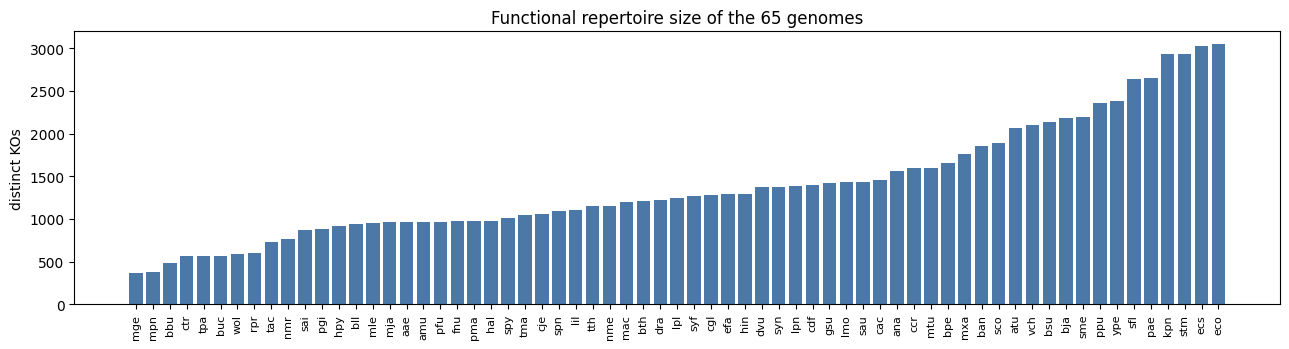

Smallest genomes:


,genome,name,n_kos
0,mge,Mycoplasmoides genitalium G37,362
1,mpn,Mycoplasmoides pneumoniae M129,377
2,bbu,Borreliella burgdorferi B31,480
3,ctr,Chlamydia trachomatis D/UW-3/CX,564
4,tpa,Treponema pallidum subsp. pallidum Nichols,570


Largest genomes:


,genome,name,n_kos
62,stm,Salmonella enterica subsp. enterica serovar Typhimurium LT2,2939
63,ecs,Escherichia coli O157:H7 Sakai (EHEC),3033
64,eco,Escherichia coli K-12 MG1655,3047


In [23]:
sizes = run_cypher("""
MATCH (g:Genome)
RETURN g.genome_id AS genome, g.name AS name, COUNT { (g)-[:CONTAINS_KO]->() } AS n_kos
ORDER BY n_kos
""")

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(sizes["genome"], sizes["n_kos"], color="#4c78a8")
ax.set_ylabel("distinct KOs"); ax.set_title("Functional repertoire size of the 65 genomes")
plt.xticks(rotation=90, fontsize=8); plt.tight_layout(); plt.show()

print("Smallest genomes:"); display(sizes.head(5))
print("Largest genomes:");  display(sizes.tail(3))

**What to notice:** repertoire sizes range from **~360 KOs** (*Mycoplasma genitalium*) to **~3,000 KOs** (*E. coli*), a factor of 8! The smallest genomes belong to *parasites and endosymbionts* (Mycoplasma, Borrelia, Chlamydia, Treponema, Buchnera, Rickettsia, Wolbachia) that live inside other cells and **threw away** functions their host provides. We will see this again in Section 7.

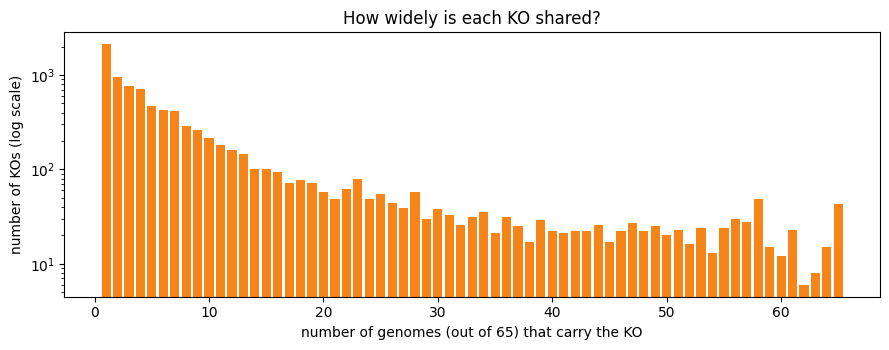

2,109 KOs occur in a single genome; 43 KOs occur in all 65.


In [24]:
prevalence = run_cypher("""
MATCH (k:KO)
RETURN COUNT { (k)<-[:CONTAINS_KO]-() } AS n_genomes_with_ko, count(*) AS n_kos
ORDER BY n_genomes_with_ko
""")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(prevalence["n_genomes_with_ko"], prevalence["n_kos"], color="#f58518")
ax.set_yscale("log")
ax.set_xlabel("number of genomes (out of 65) that carry the KO"); ax.set_ylabel("number of KOs (log scale)")
ax.set_title("How widely is each KO shared?")
plt.tight_layout(); plt.show()

only_one  = prevalence.loc[prevalence.n_genomes_with_ko == 1, "n_kos"].sum()
universal = prevalence.loc[prevalence.n_genomes_with_ko == 65, "n_kos"].sum()
print(f"{only_one:,} KOs occur in a single genome; {universal} KOs occur in all 65.")

**What to notice:** a **U-shape**, the signature of microbial **pan-genomes**: a small **core** of functions that everybody needs (here the 43 KOs found in all 65 genomes: ribosomal proteins, tRNA synthetases, chaperones, ...) and a huge **"cloud"** of rare, lineage-specific functions.

> 🧪 **Your turn.** Which 5 KOs are carried by the *fewest* genomes **but more than one**? And which non-universal KOs are the most widespread (e.g. found in 60-64 genomes)? Write the queries in the cell below.

<details><summary><b>Show solution</b></summary>

```cypher
// the most widespread KOs that are NOT universal: order by degree, skip the 65s
MATCH (k:KO)
WITH k, COUNT { (k)<-[:CONTAINS_KO]-() } AS n
WHERE n < 65
RETURN k.ko_id, k.name, k.definition, n
ORDER BY n DESC
LIMIT 10
```
Which genomes are the ones missing a *nearly universal* KO? Add `WHERE NOT (k)<-[:CONTAINS_KO]-(g)` for `MATCH (g:Genome)` to find out, usually a reduced genome that dropped it.
</details>

In [25]:
# your queries here

---
## 6 · Insight 1: which genomes are similar?

**Question Q1:** *Which genomes have similar functional repertoires?*  The graph idea: two genomes are similar if they are linked to many of the **same KO nodes**.

### 6.1 Two genomes, side by side

`COUNT { pattern }` counts how many times a pattern can be found. The pattern `(a)-[:CONTAINS_KO]->(:KO)<-[:CONTAINS_KO]-(b)` reads *"a and b both point to the same KO"*. One match per shared KO.

In [26]:
venn = run_cypher("""
MATCH (a:Genome {genome_id: $a}), (b:Genome {genome_id: $b})
WITH a, b, COUNT { (a)-[:CONTAINS_KO]->(:KO)<-[:CONTAINS_KO]-(b) } AS shared
RETURN a.name AS genome_a, COUNT { (a)-[:CONTAINS_KO]->() } AS kos_a,
       b.name AS genome_b, COUNT { (b)-[:CONTAINS_KO]->() } AS kos_b,
       shared AS shared_kos
""", a="eco", b="bsu")
venn

,genome_a,kos_a,genome_b,kos_b,shared_kos
0,Escherichia coli K-12 MG1655,3047,Bacillus subtilis subsp. subtilis 168,2133,1026


### 6.2 One genome against all others

We generalise: start from one genome, walk `Genome → KO ← Genome`, and **count the KOs on the way** for every other genome `b`.
Everything we need for a *fair* comparison is computed in one query (shared KOs and the size of both repertoires), then we sort in pandas.

In [27]:
def similar_genomes(genome_id):
    """Compare `genome_id` with every other genome that shares at least one KO."""
    return run_cypher("""
        MATCH (a:Genome {genome_id: $gid})-[:CONTAINS_KO]->(k:KO)<-[:CONTAINS_KO]-(b:Genome)
        WHERE a <> b                                  // skip the comparison with itself
        WITH a, b, count(k) AS shared                 // ONE row per pair (a, b): how many KOs are shared?
        WITH b, shared, COUNT { (a)-[:CONTAINS_KO]->() } AS size_a,
                        COUNT { (b)-[:CONTAINS_KO]->() } AS size_b
        RETURN b.genome_id AS genome, b.name AS name, shared, size_a, size_b,
               round(1.0 * shared / (size_a + size_b - shared), 3) AS jaccard
    """, gid=genome_id)

res = similar_genomes("eco")
print("Top 8 by NUMBER OF SHARED KOs")
res.sort_values("shared", ascending=False).head(8).reset_index(drop=True)

Top 8 by NUMBER OF SHARED KOs


,genome,name,shared,size_a,size_b,jaccard
0,ecs,Escherichia coli O157:H7 Sakai (EHEC),2827,3047,3033,0.869
1,stm,Salmonella enterica subsp. enterica serovar Typhimurium LT2,2555,3047,2939,0.745
2,sfl,Shigella flexneri 301 (serotype 2a),2513,3047,2644,0.791
3,kpn,Klebsiella pneumoniae subsp. pneumoniae MGH 78578 (serotype K52),2485,3047,2939,0.710
4,ype,Yersinia pestis CO92 (biovar Orientalis),2060,3047,2386,0.611
5,vch,Vibrio cholerae O1 El Tor N16961,1673,3047,2102,0.481
6,pae,Pseudomonas aeruginosa PAO1,1672,3047,2655,0.415
7,ppu,Pseudomonas putida KT2440,1649,3047,2358,0.439


The closest are the other **Enterobacteriaceae** (*E. coli* O157, *Shigella*, *Salmonella*, *Klebsiella*), the expected answer! The graph "rediscovered" taxonomy using only KO annotations.

### 6.3 Why raw counts can mislead: the Jaccard index

A genome with 3,000 KOs will share a lot with *everybody*; a genome with 400 KOs can never share more than 400. Compare *Buchnera* (an aphid endosymbiont with a tiny genome) to the rest:

In [28]:
buc = similar_genomes("buc")
print("Buchnera: top 5 by raw shared KOs");  display(buc.sort_values("shared",  ascending=False).head(5).reset_index(drop=True))
print("Buchnera: top 5 by Jaccard index");   display(buc.sort_values("jaccard", ascending=False).head(5).reset_index(drop=True))

Buchnera: top 5 by raw shared KOs


,genome,name,shared,size_a,size_b,jaccard
0,stm,Salmonella enterica subsp. enterica serovar Typhimurium LT2,565,571,2939,0.192
1,eco,Escherichia coli K-12 MG1655,563,571,3047,0.184
2,ecs,Escherichia coli O157:H7 Sakai (EHEC),562,571,3033,0.185
3,ype,Yersinia pestis CO92 (biovar Orientalis),560,571,2386,0.234
4,sfl,Shigella flexneri 301 (serotype 2a),548,571,2644,0.205


Buchnera: top 5 by Jaccard index


,genome,name,shared,size_a,size_b,jaccard
0,wol,Wolbachia endosymbiont of Drosophila melanogaster,336,571,595,0.405
1,rpr,Rickettsia prowazekii Madrid E,309,571,601,0.358
2,ctr,Chlamydia trachomatis D/UW-3/CX,294,571,564,0.350
3,aae,Aquifex aeolicus,396,571,964,0.348
4,tpa,Treponema pallidum subsp. pallidum Nichols,292,571,570,0.344


**What to notice**

* By **raw count**, the winners are big, famous genomes (*Salmonella*, *E. coli*, ...): they share ~560 of *Buchnera's* 571 KOs, but they have 3,000 KOs each, so most of what they carry is irrelevant to Buchnera.
* By **Jaccard**, the winners are *Wolbachia*, *Rickettsia*, *Chlamydia*: other small, host-dependent genomes whose repertoires have the **same shape** as Buchnera's.

The **Jaccard index** measures overlap relative to the *union* of two sets:

$$ J(A,B) \;=\; \frac{|A \cap B|}{|A \cup B|} \;=\; \frac{\text{shared}}{\text{size}_A + \text{size}_B - \text{shared}} $$

* `1.0` → identical repertoires, `0.0` → nothing in common.
* *Union = A + B − shared*, because the shared KOs would otherwise be counted twice.

> 🤔 **Think about it.** Is "similar functional repertoire" the same as "closely related"? *Buchnera* and *Chlamydia* are in different phyla, but both lost most of their metabolism after moving into host cells, a case of **convergent genome reduction**. Functional similarity captures *lifestyle* as well as *ancestry*, so we must interpret it with care.

### 6.4 All against all

Now every pair. The query returns one row per pair of genomes (`a.genome_id < b.genome_id` keeps each pair once); we normalise in pandas, which is quick for 2,080 pairs.

In [29]:
import numpy as np

pairs = run_cypher("""
MATCH (a:Genome)-[:CONTAINS_KO]->(k:KO)<-[:CONTAINS_KO]-(b:Genome)
WHERE a.genome_id < b.genome_id                       // each unordered pair exactly once
RETURN a.genome_id AS a, b.genome_id AS b, count(k) AS shared
""")
print(f"{len(pairs):,} genome pairs share at least one KO")

size = sizes.set_index("genome")["n_kos"]             # repertoire sizes from Section 5
ids = sorted(size.index)
J = pd.DataFrame(np.eye(len(ids)), index=ids, columns=ids)      # 1.0 on the diagonal (self-similarity)
for r in pairs.itertuples():
    J.loc[r.a, r.b] = J.loc[r.b, r.a] = r.shared / (size[r.a] + size[r.b] - r.shared)
J.iloc[:4, :4].round(2)

2,080 genome pairs share at least one KO


,aae,amu,ana,atu
aae,1.00,0.40,0.33,0.28
amu,0.40,1.00,0.35,0.29
ana,0.33,0.35,1.00,0.33
atu,0.28,0.29,0.33,1.00


To judge the result we need the *taxonomy* of each genome, again one **pattern** away. We ask for every ancestor of every genome at the main ranks and reshape the answer into a table with one row per genome:

In [30]:
lineage = run_cypher("""
MATCH (g:Genome)-[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(t:Taxon)
WHERE t.rank IN ['domain', 'phylum', 'class', 'order', 'family', 'genus']
RETURN g.genome_id AS genome, t.rank AS rank, t.name AS taxon
""").pivot(index="genome", columns="rank", values="taxon").fillna("")
lineage = lineage[["domain", "phylum", "class", "order", "family", "genus"]]
lineage.loc[["eco", "bsu", "syn", "mja"]]

rank,domain,phylum,class,order,family,genus
genome,,,,,,
eco,Bacteria,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Escherichia
bsu,Bacteria,Bacillota,Bacilli,Caryophanales,Bacillaceae,Bacillus
syn,Bacteria,Cyanobacteriota,Cyanophyceae,Synechococcales,Merismopediaceae,Synechocystis
mja,Archaea,Methanobacteriota,Methanococci,Methanococcales,Methanocaldococcaceae,Methanocaldococcus


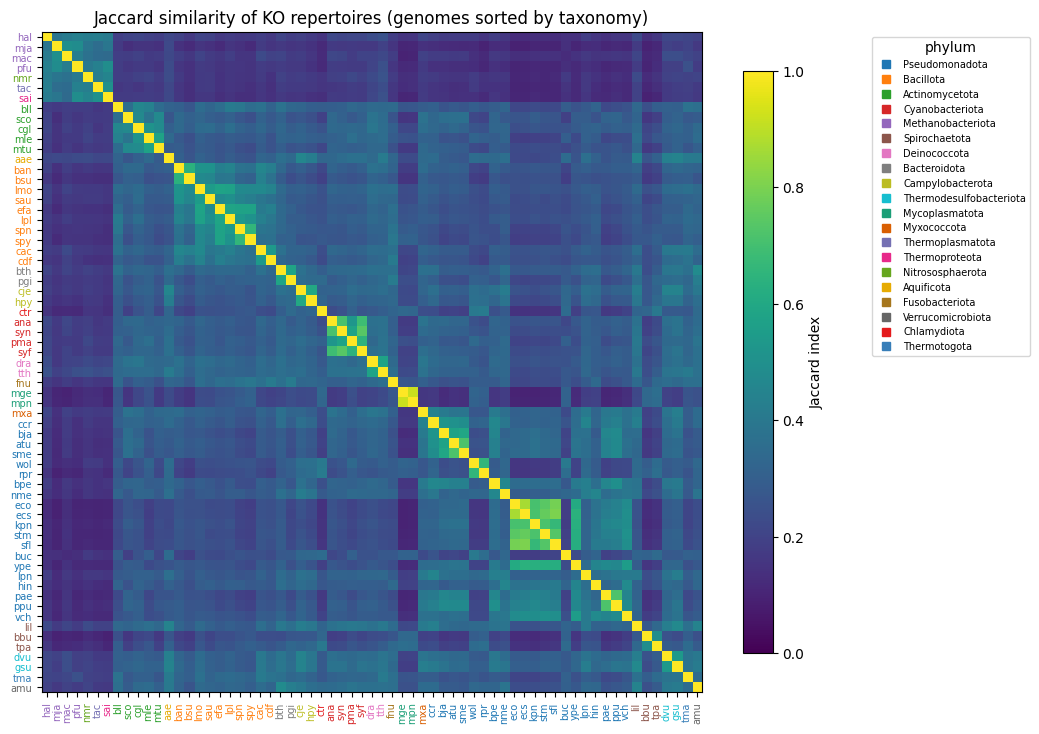

In [31]:
# ---- heat map: genomes ordered by taxonomy, so related genomes sit next to each other ----
order = lineage.sort_values(["domain", "phylum", "class", "order", "family", "genus"]).index.tolist()

phyla = lineage["phylum"].value_counts()
colours = list(plt.cm.tab10.colors) + list(plt.cm.Dark2.colors) + list(plt.cm.Set1.colors)   # strong, readable colours
palette = {p: colours[i] for i, p in enumerate(phyla.index)}               # one colour per phylum (biggest phylum first)

fig, ax = plt.subplots(figsize=(10.5, 10))
im = ax.imshow(J.loc[order, order].values, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=7)
for tick, g in zip(ax.get_xticklabels(), order): tick.set_color(palette[lineage.loc[g, "phylum"]])
for tick, g in zip(ax.get_yticklabels(), order): tick.set_color(palette[lineage.loc[g, "phylum"]])
ax.set_title("Jaccard similarity of KO repertoires (genomes sorted by taxonomy)")
fig.colorbar(im, ax=ax, shrink=0.6, label="Jaccard index")
handles = [plt.Line2D([], [], marker="s", ls="", color=c, label=p) for p, c in palette.items()]
ax.legend(handles=handles, bbox_to_anchor=(1.25, 1), loc="upper left", fontsize=7, title="phylum")
plt.tight_layout(); plt.show()

**What to notice:** *bright blocks along the diagonal* = groups of genomes that are alike, and they line up with the **taxonomy** (we sorted by taxonomy, not by similarity!). Look for the archaea in the top-left corner, the Actinomycetota, the Bacillota (a diffuse block of Gram-positives), the four cyanobacteria, the *E. coli / Shigella / Salmonella / Klebsiella* square and the almost-white *Mycoplasma* pair. The KO repertoire is a good fingerprint of ancestry.

### 6.5 Do nearest neighbours respect taxonomy?

A quantitative check. For every genome, find its **single most similar** genome and ask: *are the two in the same phylum / class / family?*

In [32]:
off_diag = J.where(~np.eye(len(J), dtype=bool))            # hide the diagonal (self-similarity = 1)
nearest = off_diag.idxmax(axis=1)                          # most similar OTHER genome for every genome

summary = {}
for rank in ["phylum", "class", "order", "family", "genus"]:
    same = lineage.loc[nearest.index, rank].values == lineage.loc[nearest.values, rank].values
    both_known = (lineage.loc[nearest.index, rank].values != "")
    summary[rank] = round(100 * same[both_known].mean())
print("% of genomes whose nearest neighbour (by KO Jaccard) shares their...")
display(pd.Series(summary, name="% same").to_frame().T)

# Fair test: a genome that is the ONLY one of its phylum in our sample cannot possibly have a same-phylum neighbour.
phylum_size = lineage["phylum"].map(lineage["phylum"].value_counts())
mismatch = pd.DataFrame({
    "genome": nearest.index, "phylum": lineage.loc[nearest.index, "phylum"].values,
    "genomes_in_phylum": phylum_size.loc[nearest.index].values,
    "nearest": nearest.values, "nearest_phylum": lineage.loc[nearest.values, "phylum"].values,
    "jaccard": [round(J.loc[g, n], 2) for g, n in nearest.items()],
}).query("phylum != nearest_phylum")
alone = (mismatch["genomes_in_phylum"] == 1).sum()
print(f"{len(mismatch)} genomes have a nearest neighbour in a DIFFERENT phylum, "
      f"but {alone} of them are the only genome of their phylum in our sample.")
mismatch.reset_index(drop=True)

% of genomes whose nearest neighbour (by KO Jaccard) shares their...


,phylum,class,order,family,genus
% same,83,70,49,26,18


11 genomes have a nearest neighbour in a DIFFERENT phylum, but 9 of them are the only genome of their phylum in our sample.


,genome,phylum,genomes_in_phylum,nearest,nearest_phylum,jaccard
0,aae,Aquificota,1,cje,Campylobacterota,0.46
1,amu,Verrucomicrobiota,1,bth,Bacteroidota,0.48
2,ctr,Chlamydiota,1,rpr,Pseudomonadota,0.42
3,fnu,Fusobacteriota,1,pgi,Bacteroidota,0.42
4,lil,Spirochaetota,3,gsu,Thermodesulfobacteriota,0.47
5,mxa,Myxococcota,1,ccr,Pseudomonadota,0.44
6,nmr,Nitrososphaerota,1,sai,Thermoproteota,0.45
7,pfu,Methanobacteriota,4,sai,Thermoproteota,0.49
8,sai,Thermoproteota,1,tac,Thermoplasmatota,0.50
9,tac,Thermoplasmatota,1,sai,Thermoproteota,0.50


**What to notice:** most genomes (about 4 out of 5) have their nearest neighbour in the *same phylum*, and the agreement is even better than it looks. Check the `genomes_in_phylum` column: most "exceptions" are phyla represented by **one single genome** in our sample (Aquifex, Akkermansia, Chlamydia, Fusobacterium, ...). They *cannot* have a same-phylum neighbour, so the method had no chance to be right. The genuinely interesting cases are the few where the phylum has several genomes, or where the neighbour is a reduced genome with a similar lifestyle (remember *Buchnera*: with strong gene loss, "similar repertoire" becomes "similar lifestyle").

Agreement drops at lower ranks (genus, family) mainly because **most genera in our sample contain just one genome**, so again there is nobody to match.

### 6.6 Hierarchical clustering: a tree *from KOs*

If KO repertoires reflect ancestry, a tree built **only from KOs** should resemble the taxonomy. We cluster genomes with distance = 1 − Jaccard (average linkage) and colour the leaf labels by phylum.

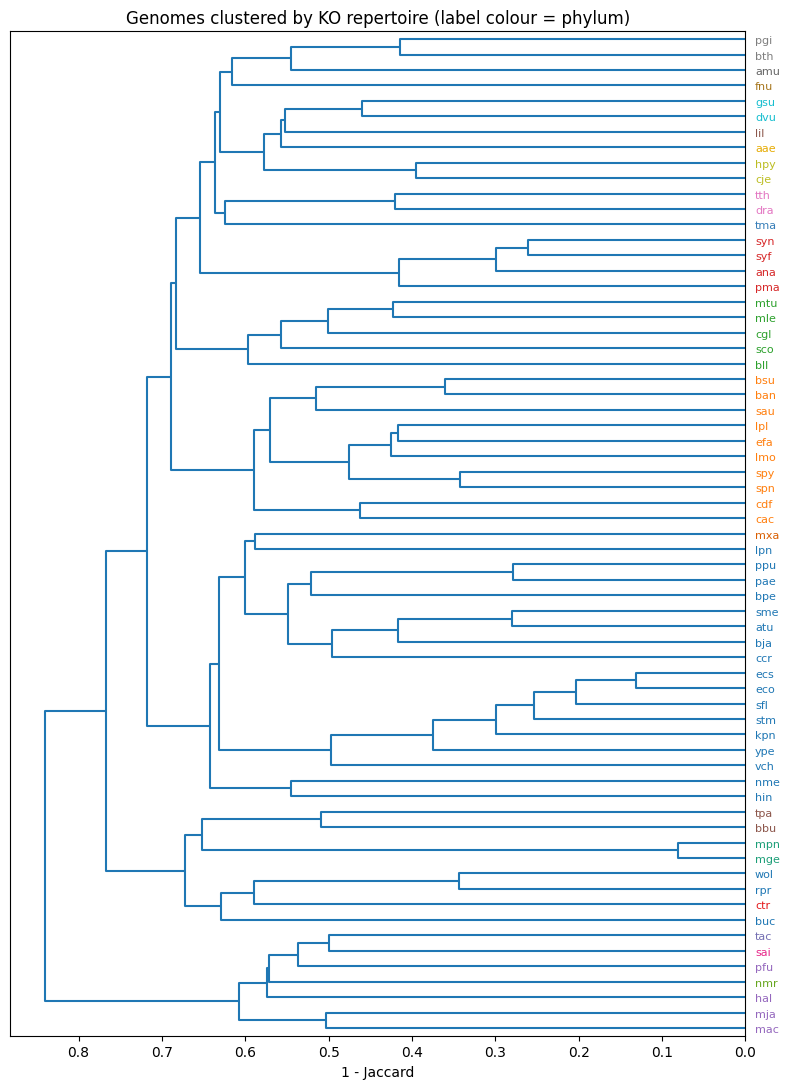

In [33]:
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

distance = 1 - J.values                                           # similarity -> distance
Z = linkage(squareform(distance, checks=False), method="average") # UPGMA: merge the two closest groups, repeat

fig, ax = plt.subplots(figsize=(8, 11))
dendrogram(Z, labels=J.index.tolist(), orientation="left", leaf_font_size=8, ax=ax, color_threshold=0)
for tick in ax.get_ymajorticklabels():
    tick.set_color(palette[lineage.loc[tick.get_text(), "phylum"]])
ax.set_xlabel("1 - Jaccard"); ax.set_title("Genomes clustered by KO repertoire (label colour = phylum)")
plt.tight_layout(); plt.show()

**What to notice:** same-coloured labels (same phylum) mostly sit together: Cyanobacteria, Bacillota, Pseudomonadota, ... **The KO graph recovers the shape of the tree of life.** (The reduced genomes drift towards each other: the convergence we discussed.)

### 6.7 Save the neighbours *in the graph*

Computing all-pairs similarity is cheap here, but on millions of genomes it is not. A very common pattern is to **materialise** a result as new relationships, so later queries can just *follow* them.
We add `(:Genome)-[:SIMILAR_TO {jaccard}]->(:Genome)` linking each genome to its **3 nearest neighbours** (a *k-nearest-neighbour graph*), computed entirely inside Neo4j:

In [34]:
run_write("MATCH ()-[s:SIMILAR_TO]->() DELETE s")        # remove old results so that the cell is safe to re-run

run_write("""
MATCH (a:Genome)-[:CONTAINS_KO]->(k:KO)<-[:CONTAINS_KO]-(b:Genome)
WHERE a <> b
WITH a, b, count(k) AS shared
WITH a, b, 1.0 * shared / (COUNT { (a)-[:CONTAINS_KO]->() } + COUNT { (b)-[:CONTAINS_KO]->() } - shared) AS jaccard
ORDER BY a.genome_id, jaccard DESC                      // sort so that the best neighbours come first ...
WITH a, collect({genome: b, jaccard: jaccard})[0..3] AS top3   // ... then keep the first three per genome
UNWIND top3 AS neighbour
WITH a, neighbour.genome AS b, neighbour.jaccard AS jaccard
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.jaccard = round(jaccard, 3)
""")
run_cypher("""
MATCH (a:Genome {genome_id: 'eco'})-[s:SIMILAR_TO]->(b:Genome)
RETURN a.name AS genome, b.name AS neighbour, s.jaccard AS jaccard ORDER BY jaccard DESC""")

 0.03s  (no changes)


 0.39s  {'relationships created': 195, 'properties set': 195}


,genome,neighbour,jaccard
0,Escherichia coli K-12 MG1655,Escherichia coli O157:H7 Sakai (EHEC),0.869
1,Escherichia coli K-12 MG1655,Shigella flexneri 301 (serotype 2a),0.791
2,Escherichia coli K-12 MG1655,Salmonella enterica subsp. enterica serovar Typhimurium LT2,0.745


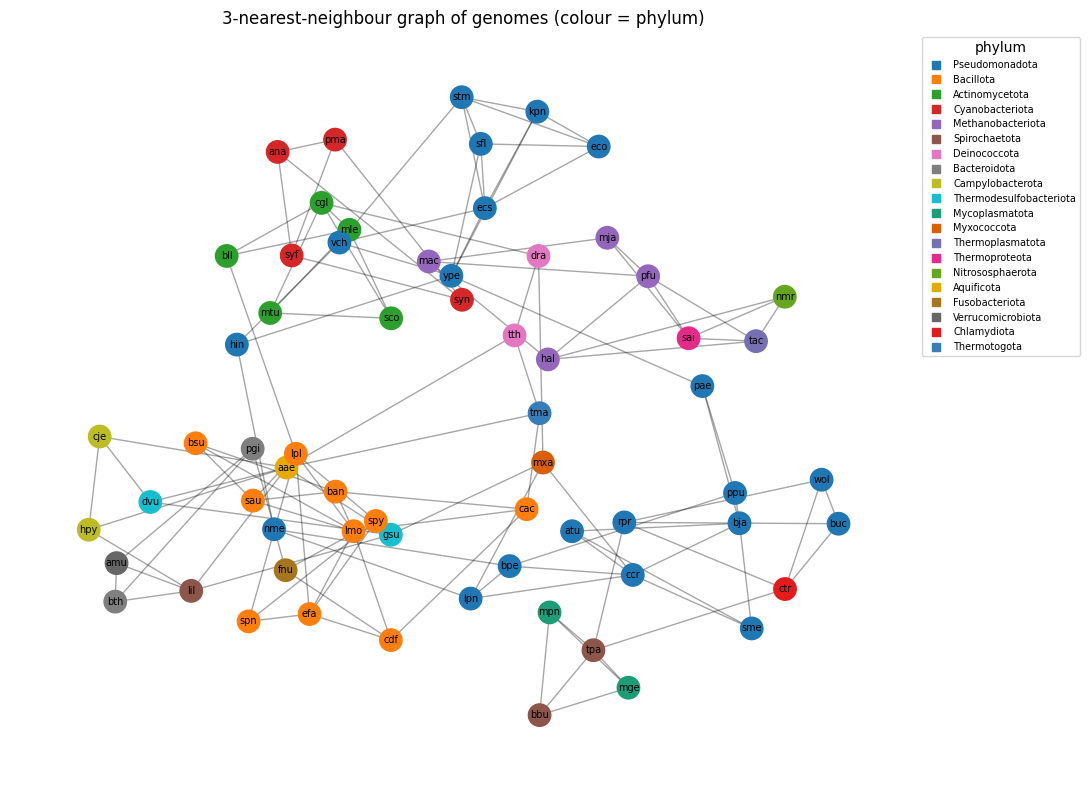

In [35]:
# ---- draw the whole kNN graph (static picture with networkx) ----
import networkx as nx

edges = run_cypher("MATCH (a:Genome)-[s:SIMILAR_TO]->(b:Genome) RETURN a.genome_id AS a, b.genome_id AS b, s.jaccard AS w")
G = nx.Graph()
G.add_weighted_edges_from(edges.itertuples(index=False, name=None))
pos = nx.spring_layout(G, weight="w", seed=7, k=0.55)            # similar genomes pulled together

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, alpha=0.35, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=[palette[lineage.loc[g, "phylum"]] for g in G.nodes], node_size=260, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=7, ax=ax)
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1), fontsize=7, title="phylum")
ax.set_title("3-nearest-neighbour graph of genomes (colour = phylum)"); ax.axis("off")
plt.tight_layout(); plt.show()

You can also explore the neighbourhood **interactively** in the database: *E. coli*, its neighbours, and the neighbours of the neighbours:

In [36]:
show_graph("""
MATCH p = (:Genome {genome_id: 'eco'})-[:SIMILAR_TO*1..2]-(:Genome)
RETURN p LIMIT 60
""", height="480px")

[Interactive graph: run this cell to draw it. The widget is not stored in the notebook file.]

> 🧪 **Your turn: Q1 exercises**
> 1. Which genome is the closest relative of *Synechocystis* (`syn`) by Jaccard, and does it make sense taxonomically?
> 2. Which **two genomes in different phyla** are the most similar to each other? *(hint: use the `pairs` DataFrame and `lineage`)*
> 3. In Cypher: list the genomes that carry **all** of `K02703` (psbA) **and** `K02588` (nifH). *(hint: two `MATCH` patterns for the same `g`)*

<details><summary><b>Show solutions</b></summary>

```python
# 1.
similar_genomes("syn").sort_values("jaccard", ascending=False).head(3)       # -> other cyanobacteria (ana, syf, pma)

# 2.
p = pairs.assign(sim=[J.loc[a, b] for a, b in zip(pairs.a, pairs.b)])
p = p[lineage.loc[p.a, "phylum"].values != lineage.loc[p.b, "phylum"].values]
p.sort_values("sim", ascending=False).head(5)
```
```cypher
// 3.  two patterns sharing the variable g = "AND"
MATCH (g:Genome)-[:CONTAINS_KO]->(:KO {ko_id: 'K02703'}),
      (g)-[:CONTAINS_KO]->(:KO {ko_id: 'K02588'})
RETURN g.name        // -> Nostoc (Anabaena) sp. PCC 7120: a nitrogen-fixing cyanobacterium
```
</details>

### 6.8 Takeaways of Insight 1

* A **similarity search is a 2-hop pattern**: `Genome → KO ← Genome`. No join tables, no self-join.
* **Normalise** (Jaccard) before you interpret counts.
* Graph results can be **written back** (`SIMILAR_TO`) and queried again; the graph grows richer as you analyse.
* Functional similarity mirrors, but is not identical to, ancestry.

---
## 7 · Insight 2: how did KOs evolve across the tree?

**Question Q2:** *How are KOs distributed over the tree of life?*
Some functions are **ancestral** (present in the common ancestor of everything and kept), some are **innovations** of one clade (a single gain, then inherited by all descendants), and some are **patchy** (found here and there, because of repeated loss or horizontal gene transfer).

### 7.1 The tree as a path: variable-length patterns

The magic is in `-[:CHILD_OF*]->`, *"follow `CHILD_OF` as many times as needed"*:

| pattern | meaning |
|---|---|
| `-[:CHILD_OF]->` | exactly one step up (the parent) |
| `-[:CHILD_OF*2]->` | exactly two steps up |
| `-[:CHILD_OF*1..3]->` | between one and three steps |
| `-[:CHILD_OF*]->` | one or more steps (all ancestors) |
| `-[:CHILD_OF*0..]->` | zero or more steps (**the node itself** and all its ancestors) |

> In a graph **with cycles** an unbounded `*` can explode in time and memory. Our tree has no cycles, so it is safe, but get used to bounding long paths (`*..10`) in your own graphs.

The lineage of *E. coli* as a table (one row per ancestor):

In [37]:
run_cypher("""
MATCH p = (:Genome {genome_id: $gid})-[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(:Taxon {rank: 'root'})
UNWIND nodes(p)[1..] AS t                      // nodes(p)[0] is the genome itself, so skip it
RETURN t.rank_level AS level, t.rank AS rank, t.name AS taxon
ORDER BY level
""", gid="eco")

,level,rank,taxon
0,0,root,cellular organisms
1,1,domain,Bacteria
2,2,phylum,Pseudomonadota
3,3,class,Gammaproteobacteria
4,4,order,Enterobacterales
5,5,family,Enterobacteriaceae
6,6,genus,Escherichia
7,7,species,Escherichia coli


### 7.2 How many genomes live under each clade?

We will need this number repeatedly, so we compute it **once** and store it as a property `n_genomes` on each `Taxon` (a small *enrichment*; the graph remains the source of truth, this is a cache).

* `OPTIONAL MATCH` is like a SQL **LEFT JOIN**: taxa with no genome below them stay in the result with a count of 0.
* `count(DISTINCT g)` counts each genome once.

 0.06s  {'properties set': 270}


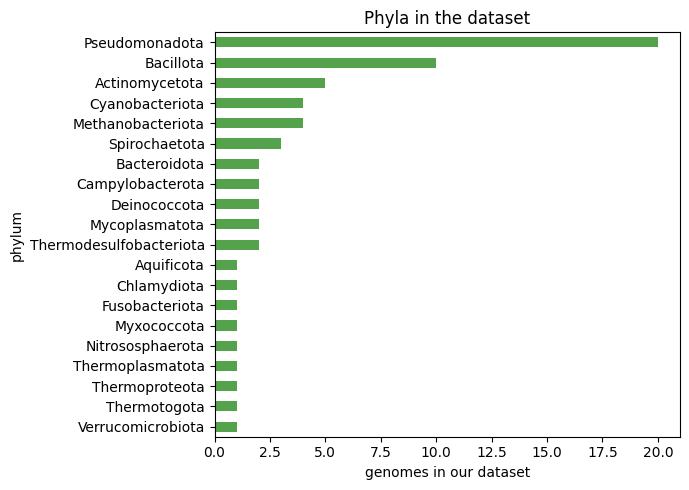

In [38]:
run_write("""
MATCH (t:Taxon)
OPTIONAL MATCH (g:Genome)-[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(t)
WITH t, count(DISTINCT g) AS n
SET t.n_genomes = n
""")

clades = run_cypher("""
MATCH (t:Taxon {rank: 'phylum'})
RETURN t.name AS phylum, t.n_genomes AS genomes ORDER BY genomes DESC, phylum""")
ax = clades.set_index("phylum")["genomes"].iloc[::-1].plot.barh(figsize=(7, 5), color="#54a24b")
ax.set_xlabel("genomes in our dataset"); ax.set_title("Phyla in the dataset"); plt.tight_layout(); plt.show()

Our sample is **biased** (many Proteobacteria and Firmicutes, because those contain the famous model organisms and pathogens). Keep that in mind when interpreting *"X is rare"*.

### 7.3 Where in the tree is a KO found?

Walk **up** from every genome that carries the KO to the clades above it, then count per clade. The result for one KO and one rank:

In [39]:
def ko_by_clade(ko_id, rank="phylum"):
    """For each clade of the given rank that contains >= 1 carrier: how many of its genomes carry the KO?"""
    return run_cypher("""
        MATCH (k:KO {ko_id: $ko})<-[:CONTAINS_KO]-(g:Genome)
              -[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(clade:Taxon {rank: $rank})
        WITH clade, count(DISTINCT g) AS with_ko
        RETURN clade.name AS clade, clade.n_genomes AS clade_size, with_ko,
               round(1.0 * with_ko / clade.n_genomes, 2) AS fraction
        ORDER BY fraction DESC, with_ko DESC
    """, ko=ko_id, rank=rank)

focus = {"K02703": "psbA  (photosystem II D1: photosynthesis)",
         "K07699": "spo0A (master regulator of sporulation)",
         "K02588": "nifH  (nitrogenase: fixes N2 gas)",
         "K04077": "groEL (chaperonin; essential)"}
for ko, label in focus.items():
    print(f"\n=== {ko} · {label}")
    display(ko_by_clade(ko, "phylum"))


=== K02703 · psbA  (photosystem II D1: photosynthesis)


,clade,clade_size,with_ko,fraction
0,Cyanobacteriota,4,4,1.0



=== K07699 · spo0A (master regulator of sporulation)


,clade,clade_size,with_ko,fraction
0,Bacillota,10,4,0.4



=== K02588 · nifH  (nitrogenase: fixes N2 gas)


,clade,clade_size,with_ko,fraction
0,Thermodesulfobacteriota,2,2,1.00
1,Fusobacteriota,1,1,1.00
2,Methanobacteriota,4,2,0.50
3,Cyanobacteriota,4,1,0.25
4,Pseudomonadota,20,2,0.10
5,Bacillota,10,1,0.10



=== K04077 · groEL (chaperonin; essential)


,clade,clade_size,with_ko,fraction
0,Pseudomonadota,20,20,1.0
1,Bacillota,10,10,1.0
2,Actinomycetota,5,5,1.0
3,Cyanobacteriota,4,4,1.0
4,Methanobacteriota,4,4,1.0
5,Spirochaetota,3,3,1.0
6,Deinococcota,2,2,1.0
7,Bacteroidota,2,2,1.0
8,Campylobacterota,2,2,1.0
9,Thermodesulfobacteriota,2,2,1.0


**Three different evolutionary stories, one query:**

| KO | what the tree shows | story |
|---|---|---|
| **psbA** | only in *Cyanobacteriota*, and in **all 4** of them (fraction 1.0) | **one innovation**, inherited by the whole clade |
| **spo0A** | only in *Bacillota*, but only 4 of its 10 genomes (fraction 0.4) | an innovation of a **sub-group** (the spore-formers); other Bacillota lost it or never had it |
| **nifH** | 9 genomes spread over **6 phyla and both domains**; a minority within the large phyla (2 of 20 Pseudomonadota, 1 of 10 Bacillota), complete only where the phylum has just 1-2 genomes | **patchy**: an old gene lost many times and/or moved between lineages by horizontal transfer |
| **groEL** | everywhere | **ancestral & essential** |

### 7.4 From a table to a single number: the *origin clade*

Can we summarise "where does this KO live in the tree" in one relationship? Use **parsimony** ("the simplest explanation"):

> Find the **smallest clade that contains every genome with the KO** (their *lowest common ancestor*, LCA). The simplest story is that the KO first appeared in the ancestor of that clade.
> Then measure the **coverage** = (genomes with KO) / (all genomes in that clade).

```mermaid
graph TD
    R((root)) --> A((clade A)) & B((clade B))
    A --> a1["a1 ✔"] & a2["a2 ✔"] & a3["a3 ✔"]
    B --> b1["b1 ✘"] & b2["b2 ✘"]
    classDef has fill:#b7e1a1,stroke:#2d7d2d,color:#000
    classDef no fill:#eee,stroke:#999,color:#555
    class a1,a2,a3 has
    class b1,b2 no
```

* **KO found in a1, a2, a3.** Smallest clade containing them = **clade A**; coverage = 3/3 = **1.0** → *one gain in the ancestor of A, inherited by everyone*.
* **KO found in a1 and b2.** Smallest clade containing them = **root**; coverage = 2/5 = **0.4** → *patchy*: either gained at the root and lost 3 times, or gained twice independently (or transferred).

We compute the LCA for **all 8,994 KOs at once** and store it as a new relationship `(:KO)-[:ORIGIN_CLADE {carriers, clade_size, coverage}]->(:Taxon)`. Read the query top-down:

1. `collect(g)` gathers the **carrier** genomes of each KO.
2. For each carrier, walk **up** (`CHILD_OF*0..`) to every ancestor `t`, and count how many carriers sit under `t`.
3. Keep the ancestors that sit above **all** carriers (`n_under = n`). They are the *common ancestors*.
4. Order them by `rank_level` (deepest first) and take the first: the **lowest** common ancestor.

In [40]:
run_write("MATCH ()-[o:ORIGIN_CLADE]->() DELETE o")       # re-runnable

run_write("""
MATCH (k:KO)<-[:CONTAINS_KO]-(g:Genome)
WITH k, collect(g) AS carriers                                              // step 1
UNWIND carriers AS g
MATCH (g)-[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(t:Taxon)             // step 2
WITH k, size(carriers) AS n, t, count(DISTINCT g) AS n_under
WHERE n_under = n                                                           // step 3: ancestors of ALL carriers
WITH k, n, t ORDER BY t.rank_level DESC                                     // step 4: deepest first ...
WITH k, n, collect(t)[0] AS lca                                             //         ... keep the first
MERGE (k)-[o:ORIGIN_CLADE]->(lca)
SET o.carriers = n, o.clade_size = lca.n_genomes, o.coverage = round(1.0 * n / lca.n_genomes, 3)
""")

 0.01s  (no changes)


 0.89s  {'relationships created': 8994, 'properties set': 26982}


### 7.5 Classify every KO by its evolutionary pattern

With one relationship per KO the classification is a simple `CASE` expression:

| pattern | rule |
|---|---|
| **private** | the origin clade is a single species (KO in one genome or in two strains of one species) |
| **universal** | origin clade is the root and coverage ≥ 0.9 |
| **clade-specific, conserved** | origin clade is below the root and coverage ≥ 0.9 |
| **mostly conserved** | coverage between 0.5 and 0.9 |
| **patchy** | coverage < 0.5 |

*The thresholds (0.9, 0.5) are our own choice: change them and see how the numbers move!*

,pattern,kos,share_%
0,1 private (one species),2134,23.7
1,2 universal,122,1.4
2,"3 clade-specific, conserved",835,9.3
3,4 mostly conserved,1738,19.3
4,5 patchy,4165,46.3


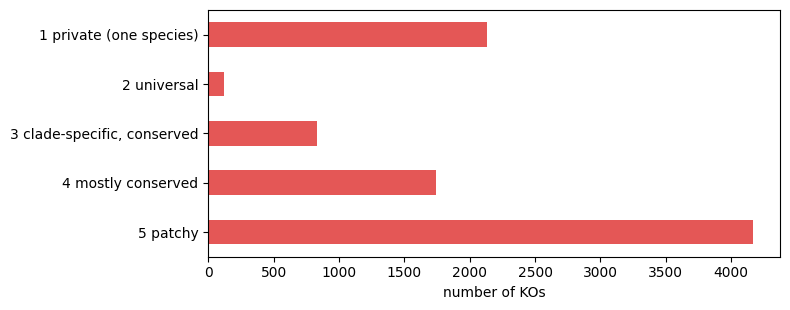

In [41]:
patterns = run_cypher("""
MATCH (k:KO)-[o:ORIGIN_CLADE]->(t:Taxon)
RETURN CASE WHEN t.rank = 'species'                       THEN '1 private (one species)'
            WHEN t.rank_level = 0 AND o.coverage >= 0.9   THEN '2 universal'
            WHEN o.coverage >= 0.9                        THEN '3 clade-specific, conserved'
            WHEN o.coverage >= 0.5                        THEN '4 mostly conserved'
            ELSE                                               '5 patchy' END AS pattern,
       count(*) AS kos
ORDER BY pattern
""")
patterns["share_%"] = (100 * patterns["kos"] / patterns["kos"].sum()).round(1)
display(patterns)

ax = patterns.set_index("pattern")["kos"].iloc[::-1].plot.barh(figsize=(8, 3.2), color="#e45756")
ax.set_xlabel("number of KOs"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

**What to notice:** only a **small fraction** of KOs is universal or a clean clade-specific innovation; most KOs are **patchy**. The "flexible" part of bacterial genomes is shaped by horizontal gene transfer and repeated gene loss, not by tidy inheritance. This is why microbial evolution is often called *a network, not a tree*.

### 7.6 Case studies with the origin-clade relationship

In [42]:
run_cypher("""
MATCH (k:KO)-[o:ORIGIN_CLADE]->(t:Taxon)
WHERE k.ko_id IN $kos
RETURN k.name AS ko, k.definition AS function, o.carriers AS genomes_with_ko,
       t.name AS origin_clade, t.rank AS rank, o.clade_size AS clade_size, o.coverage AS coverage
ORDER BY coverage DESC, genomes_with_ko DESC
""", kos=["K04077", "K03043", "K02703", "K07699", "K02406", "K02588"])

,ko,function,genomes_with_ko,origin_clade,rank,clade_size,coverage
0,groEL,chaperonin GroEL [EC:5.6.1.7],65,cellular organisms,root,65,1.000
1,psbA,photosystem II P680 reaction center D1 protein [EC:1.10.3.9],4,Cyanophyceae,class,4,1.000
2,rpoB,DNA-directed RNA polymerase subunit beta [EC:2.7.7.6],55,Bacteria,domain,58,0.948
3,fliC,flagellin,28,Bacteria,domain,58,0.483
4,spo0A,"two-component system, response regulator, stage 0 sporulation prot...",4,Bacillota,phylum,10,0.400
5,nifH,nitrogenase iron protein NifH,9,cellular organisms,root,65,0.138


| KO | origin clade | coverage | reading |
|---|---|---|---|
| groEL | root | 1.0 | **ancestral**: in all 65 |
| rpoB | Bacteria | ~0.95 | **ancestral to Bacteria** (archaea use a different RNA polymerase gene) |
| psbA | Cyanophyceae (= all cyanobacteria) | 1.0 | **clade innovation**: textbook single gain |
| spo0A | Bacillota | 0.4 | an innovation of a subgroup (spore formers), partially lost |
| fliC | Bacteria | ~0.5 | **patchy**: flagella gained/lost repeatedly |
| nifH | root | 0.14 | **very patchy**: nitrogen fixation scattered over the tree |

> 💡 *Why "Cyanophyceae" and not "Cyanobacteriota"?* In our sample the phylum has just one class, so both clades contain the same 4 genomes. We take the **deepest** clade that fits (highest `rank_level`).

### 7.7 Signature KOs: what defines a clade?

*Which KOs are present in **every** member of a clade, and only there?* These are the clade's *signature* functions.

Using `ORIGIN_CLADE` this is a clean condition: the KO's origin clade must be the clade **or a clade inside it** (a job for `CHILD_OF*0..`), **and** the number of carriers must equal the number of genomes in the clade (`o.carriers = c.n_genomes`): every member has it and nobody outside does.

In [43]:
def signature_kos(clade_name, min_carriers=3):
    """KOs found in ALL genomes of `clade_name` and in no genome outside it."""
    return run_cypher("""
        MATCH (k:KO)-[o:ORIGIN_CLADE]->(:Taxon)-[:CHILD_OF*0..]->(c:Taxon {name: $clade})
        WHERE o.carriers = c.n_genomes AND o.carriers >= $min_carriers   // all members have it; ignore tiny clades
        RETURN k.ko_id AS ko, k.name AS name, k.definition AS function
        ORDER BY name
    """, clade=clade_name, min_carriers=min_carriers)

sig = signature_kos("Cyanobacteriota")
print(f"{len(sig)} signature KOs of the Cyanobacteriota. A few of them:")
sig.sample(8, random_state=1)

104 signature KOs of the Cyanobacteriota. A few of them:


,ko,name,function
96,K02722,psbX,photosystem II PsbX protein
35,K25172,hgdD,heterocyst glycolipid deposition protein
81,K02704,psbB,photosystem II CP47 chlorophyll apoprotein
59,K02635,petB,cytochrome b6
38,K20024,mgdE,monoglucosyldiacylglycerol epimerase [EC:5.1.3.34]
39,K07769,nblS,"two-component system, OmpR family, sensor histidine kinase NblS [E..."
53,K05585,ndhN,NAD(P)H-quinone oxidoreductase subunit N [EC:7.1.1.2]
85,K02708,psbF,photosystem II cytochrome b559 subunit beta


A random sample of KO names is hard to read, so add the third hop `KO → Pathway` to get the **big picture**. Which pathways do the cyanobacterial signature KOs belong to?

In [44]:
run_cypher("""
MATCH (k:KO)-[o:ORIGIN_CLADE]->(:Taxon)-[:CHILD_OF*0..]->(c:Taxon {name: $clade})
WHERE o.carriers = c.n_genomes AND o.carriers >= 3
MATCH (k)-[:IN_PATHWAY]->(p:Pathway)
RETURN p.name AS pathway, count(DISTINCT k) AS signature_kos
ORDER BY signature_kos DESC LIMIT 8
""", clade="Cyanobacteriota")

,pathway,signature_kos
0,Photosynthesis,38
1,Oxidative phosphorylation,14
2,Porphyrin metabolism,10
3,Carotenoid biosynthesis,5
4,Ubiquinone and other terpenoid-quinone biosynthesis,4
5,Glycerolipid metabolism,4
6,Two-component system,4
7,Sulfoquinovose metabolism,2


The top pathway, **Photosynthesis**, is the signature of the clade: see which KOs it contains. Names such as *psaA…psaL* (photosystem I), *psbA…psbZ* (photosystem II) and *petA…petN* (cytochrome b6f) are the textbook machinery of oxygenic photosynthesis, inherited **together** from a common ancestor. Neo4j knows no biology: the tree and the KO links were enough.

In [45]:
run_cypher("""
MATCH (k:KO)-[o:ORIGIN_CLADE]->(:Taxon)-[:CHILD_OF*0..]->(c:Taxon {name: $clade})
WHERE o.carriers = c.n_genomes AND o.carriers >= 3
MATCH (k)-[:IN_PATHWAY]->(:Pathway {name: 'Photosynthesis'})
RETURN k.name AS ko, k.definition AS function
ORDER BY ko LIMIT 12
""", clade="Cyanobacteriota")

,ko,function
0,petA,apocytochrome f
1,petB,cytochrome b6
2,petD,cytochrome b6-f complex subunit 4
3,petE,plastocyanin
4,petF,ferredoxin
5,petG,cytochrome b6-f complex subunit 5
6,petM,cytochrome b6-f complex subunit 7
7,petN,cytochrome b6-f complex subunit 8
8,psaA,photosystem I P700 chlorophyll a apoprotein A1 [EC:1.97.1.12]
9,psaB,photosystem I P700 chlorophyll a apoprotein A2 [EC:1.97.1.12]


Which clades have the most signature KOs? *(clades with ≥ 3 genomes, at class or phylum level)*

In [46]:
sig_counts = run_cypher("""
MATCH (k:KO)-[o:ORIGIN_CLADE]->(:Taxon)-[:CHILD_OF*0..]->(c:Taxon)
WHERE c.rank IN ['phylum', 'class'] AND c.n_genomes >= 3 AND o.carriers = c.n_genomes
RETURN c.rank AS rank, c.name AS clade, c.n_genomes AS genomes, count(DISTINCT k) AS signature_kos
ORDER BY signature_kos DESC LIMIT 10
""")
sig_counts

,rank,clade,genomes,signature_kos
0,class,Cyanophyceae,4,104
1,phylum,Cyanobacteriota,4,104
2,class,Bacilli,8,18
3,class,Actinomycetes,5,14
4,phylum,Actinomycetota,5,14
5,class,Alphaproteobacteria,6,8
6,phylum,Bacillota,10,6
7,phylum,Methanobacteriota,4,6
8,phylum,Spirochaetota,3,1
9,phylum,Pseudomonadota,20,1


> 🧪 **Your turn.** Use `signature_kos(...)` on **`Bacillota`** (Firmicutes) and on **`Archaea`**. What functions define them? Does the result match what you know about these groups? Try `min_carriers=2`: what changes, and why is a low `min_carriers` risky?

<details><summary><b>Show a hint</b></summary>

With only 2 carriers, "every genome of the clade has it" is *easy to satisfy by chance*: two genomes that happen to share a gene look like a clade-specific innovation. More genomes → more convincing evidence. This is the same reason statisticians ask for sample sizes.
</details>

In [47]:
# your experiments here

### 7.8 Genome reduction: the core of a clade shrinks as you go up the tree

A KO belongs to the **core** of a clade if ≥ 90% of its genomes carry it. We walk up the lineage of *E. coli* and measure the core size at every level. We expect: *the broader the clade, the smaller the shared core*.

,level,rank,clade,genomes,core_kos
0,0,root,cellular organisms,65,122
1,1,domain,Bacteria,58,232
2,2,phylum,Pseudomonadota,20,500
3,3,class,Gammaproteobacteria,12,708
4,4,order,Enterobacterales,7,518
5,5,family,Enterobacteriaceae,5,2071


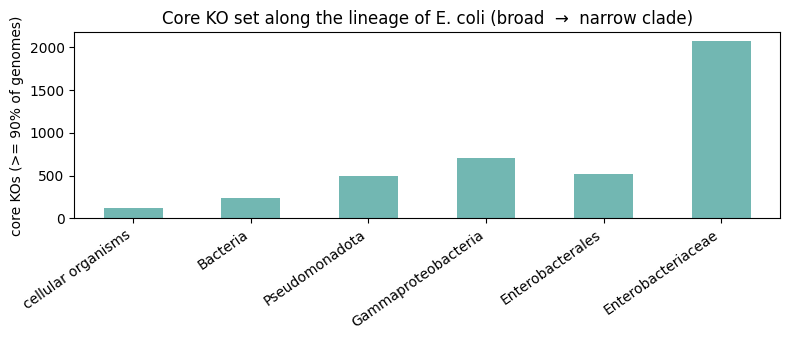

In [48]:
core = run_cypher("""
MATCH (:Genome {genome_id: $gid})-[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(c:Taxon)
WHERE c.n_genomes >= 3                                  // skip tiny clades: 'core of 1 genome' means nothing
MATCH (m:Genome)-[:CLASSIFIED_AS]->(:Taxon)-[:CHILD_OF*0..]->(c)
WITH c, collect(DISTINCT m) AS members
UNWIND members AS m
MATCH (m)-[:CONTAINS_KO]->(k:KO)
WITH c, size(members) AS n, k, count(*) AS n_with       // in how many members is each KO found?
WHERE n_with >= 0.9 * n                                 // 'core' = found in >= 90% of the clade
RETURN c.rank_level AS level, c.rank AS rank, c.name AS clade, n AS genomes, count(k) AS core_kos
ORDER BY level
""", gid="eco")
display(core)

ax = core.plot(x="clade", y="core_kos", kind="bar", legend=False, figsize=(8, 3.5), color="#72b7b2")
ax.set_ylabel("core KOs (>= 90% of genomes)"); ax.set_xlabel("")
ax.set_title("Core KO set along the lineage of E. coli (broad  →  narrow clade)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

**What to notice**

* From the root down to *Gammaproteobacteria* the core **grows** (122 → 232 → 500 → 700 KOs): narrower groups share more.
* Then comes a **surprise**: *Enterobacterales* has a *smaller* core than *Enterobacteriaceae* (~500 vs ~2,000). Why? The order also contains **Buchnera**, the aphid endosymbiont with only ~570 KOs. A KO can only be in the core if (almost) *every* member has it, so **one heavily reduced genome caps the core of the whole clade**. This is genome reduction made visible.

### 7.9 Gene loss between close relatives

*Mycobacterium tuberculosis* and *M. leprae* (leprosy) are close relatives, yet *M. leprae* has a famously decayed genome. Which KOs did it lose, and *did it gain any*?

In [49]:
lost = run_cypher("""
MATCH (a:Genome {genome_id: 'mtu'})-[:CONTAINS_KO]->(k:KO)
WHERE NOT EXISTS { (:Genome {genome_id: 'mle'})-[:CONTAINS_KO]->(k) }     // "a has it, b does NOT"
RETURN count(k) AS in_mtu_but_not_mle""")
gained = run_cypher("""
MATCH (b:Genome {genome_id: 'mle'})-[:CONTAINS_KO]->(k:KO)
WHERE NOT EXISTS { (:Genome {genome_id: 'mtu'})-[:CONTAINS_KO]->(k) }
RETURN count(k) AS in_mle_but_not_mtu""")
display(lost); display(gained)

,in_mtu_but_not_mle
0,668


,in_mle_but_not_mtu
0,15


The number of KOs found only in *M. leprae* is tiny compared with those it lost: **reductive evolution** is mostly *loss*. What kinds of functions disappeared? Add the `Pathway` hop:

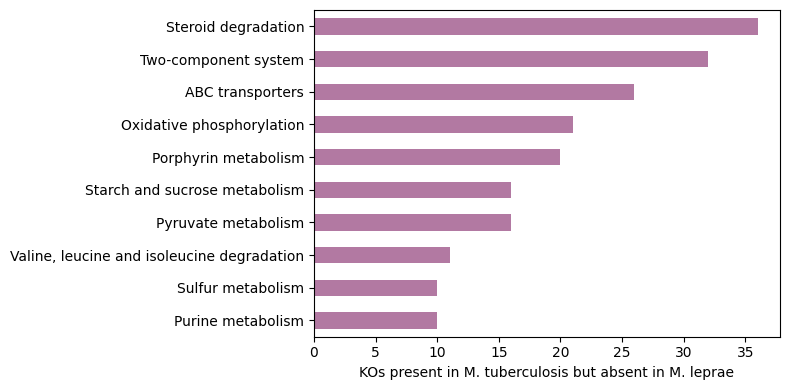

In [50]:
lost_pathways = run_cypher("""
MATCH (:Genome {genome_id: 'mtu'})-[:CONTAINS_KO]->(k:KO)
WHERE NOT EXISTS { (:Genome {genome_id: 'mle'})-[:CONTAINS_KO]->(k) }
MATCH (k)-[:IN_PATHWAY]->(p:Pathway)
RETURN p.name AS pathway, count(DISTINCT k) AS lost_kos
ORDER BY lost_kos DESC LIMIT 10
""")
ax = lost_pathways.set_index("pathway")["lost_kos"].iloc[::-1].plot.barh(figsize=(8, 4), color="#b279a2")
ax.set_xlabel("KOs present in M. tuberculosis but absent in M. leprae"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Steroid degradation, ABC transporters, two-component signalling, oxidative phosphorylation ... *M. leprae* lives inside human cells and nerves, where it no longer needs to catabolise diverse nutrients or sense a changing environment.

> 🧪 **Your turn (challenge).** Pick **another pair** of related genomes, e.g. *Mycoplasma pneumoniae* (`mpn`) vs *Bacillus subtilis* (`bsu`), or *Rickettsia* (`rpr`) vs *Caulobacter* (`ccr`) and repeat 7.9. Which pathways does the reduced genome keep? *(Hint: replace the genome ids; for "KOs kept in both", drop the `NOT`.)*

### 7.10 Takeaways of Insight 2

* **A tree is just nodes and `CHILD_OF` relationships**; variable-length paths (`*0..`) answer any ancestor / descendant question in one line.
* Combining **tree + annotations** reveals evolutionary *patterns*: ancestral, clade-specific, patchy.
* **Materialise** useful intermediate results (`n_genomes`, `ORIGIN_CLADE`) as properties/relationships. The next queries become short and fast.
* Always ask *"what could bias this?"*: sample composition, annotation gaps, the difference between taxonomy and phylogeny.

---
## 8 · Wrap-up

### 8.1 What did we learn?

| Objective | What we did |
|---|---|
| **Model genomic data as a graph** | whiteboard recipe → `Genome`, `KO`, `Taxon`, `Pathway` nodes; `CONTAINS_KO`, `CLASSIFIED_AS`, `CHILD_OF`, `IN_PATHWAY` relationships; properties on nodes *and* relationships |
| **Build a genomic graph database with Neo4j** | constraints → batch `UNWIND … MERGE` import → verification against the CSV row counts |
| **Identify similar genomes** from shared KOs | `Genome → KO ← Genome` pattern, Jaccard index, heat map, dendrogram, kNN graph |
| **Infer evolutionary patterns of KOs across a phylogenetic structure** | variable-length `CHILD_OF*` paths, lowest common ancestor, origin clade + coverage, signature KOs, core shrinkage, gene loss |

### 8.2 Limits of this analysis (be a sceptical scientist)

* **Taxonomy ≠ phylogeny.** A real tree is inferred from sequence alignments (for example the GTDB tree). The same graph model works: just replace `taxon_tree.csv` by the nodes and branches of a Newick tree (with branch lengths as relationship properties).
* **KO annotation is incomplete and biased** towards well-studied organisms; *absent* in the table can mean *not annotated*.
* **Presence/absence ignores gene order, copy number and sequence divergence.**
* **Our 65 genomes are a small, uneven sample**: clade-level statements for single-genome clades are anecdotes.
* **Parsimony is a simplification.** Horizontal gene transfer breaks the "one gain, inherited" assumption; patchy KOs are exactly where it matters.

### 8.3 Where to go next

* **Neo4j Graph Data Science (GDS)** library: community detection (Louvain), node similarity, PageRank, node embeddings → run Q1 on thousands of genomes.
* **Add more node types**: genes, proteins (UniProt), phenotypes, habitats, antibiotic-resistance genes. Each new type is a new *label* + a few relationships, no schema migration.
* **Pangenome graphs** (like the *pgv* example in the lecture): the genome sequence itself as a graph.
* **Knowledge graphs** such as [Hetionet](https://neo4j.het.io) (the network from the lecture): genes, diseases, drugs, tissues, ... in one graph.

### 8.4 Reset or clean up

* *Keep exploring tomorrow?* Nothing to do: the data lives in a Docker **volume** and survives restarts (`docker compose stop` / `start`).
* *Start again from scratch?* Re-run [Section 4](#4--import-build-the-real-graph) (it begins by emptying the database), or run `docker compose down -v` in the `docker/` folder to delete everything.

In [51]:
driver.close()      # polite: closes the network connections (the data stays in the database)

---
## Appendix A · Cypher cheat sheet

```cypher
// ---- READ ----------------------------------------------------------------
MATCH (g:Genome)                       RETURN g LIMIT 5                  // all nodes with a label
MATCH (g:Genome {genome_id:'eco'})     RETURN g.name                     // filter by a property
MATCH (g:Genome) WHERE g.n_protein_genes > 4000 RETURN g.name            // WHERE for any condition
MATCH (g)-[r:CONTAINS_KO]->(k)         RETURN g, r, k LIMIT 10           // follow a relationship
MATCH (a)-[:CONTAINS_KO]->(k)<-[:CONTAINS_KO]-(b)  WHERE a <> b ...      // two hops: shared neighbour
MATCH (g)-[:CLASSIFIED_AS]->()-[:CHILD_OF*0..]->(clade) ...              // variable-length path
MATCH p = (a)-[*..4]-(b) RETURN p                                        // a path, 1 to 4 hops (any direction)
OPTIONAL MATCH ...                                                       // like a LEFT JOIN
WHERE NOT EXISTS { (g)-[:CONTAINS_KO]->(k) }                             // "has no such relationship"
COUNT { (g)-[:CONTAINS_KO]->() }                                         // count matches of a pattern (degree)

// ---- AGGREGATE & SHAPE ---------------------------------------------------------
RETURN x, count(*) AS n          // any non-aggregated column is the GROUP BY key
RETURN collect(k.name)           // gather values into a list
WITH x, count(*) AS n WHERE n>1  // WITH = pipe the result into the next part (like HAVING / subquery)
ORDER BY n DESC  SKIP 10  LIMIT 5
UNWIND $list AS item             // one row per list element (the opposite of collect)

// ---- WRITE ---------------------------------------------------------------------
CREATE (:Genome {genome_id:'xyz'})            // always creates
MERGE  (g:Genome {genome_id:'xyz'})           // get-or-create (idempotent)
MERGE  (g)-[:CONTAINS_KO {copies:1}]->(k)
SET    g.name = 'New name'                    // set / overwrite a property
REMOVE g.name                                 // delete a property
DETACH DELETE g                               // delete a node and its relationships
CREATE CONSTRAINT x IF NOT EXISTS FOR (g:Genome) REQUIRE g.genome_id IS UNIQUE
```

| Cypher | SQL analogue |
|---|---|
| `MATCH (g:Genome)` | `FROM genomes g` |
| `(a)-[:R]->(b)` | `JOIN ... ON` (but the join is stored, not computed) |
| `WHERE` | `WHERE` |
| `RETURN a, count(*)` | `SELECT a, COUNT(*) ... GROUP BY a` |
| `WITH ... WHERE` | `HAVING` / sub-select |
| `OPTIONAL MATCH` | `LEFT JOIN` |
| `MERGE` | `INSERT ... ON CONFLICT DO NOTHING / UPDATE` |
| `-[:R*]->` | `WITH RECURSIVE` |

Official reference card: <https://neo4j.com/docs/cypher-cheat-sheet/>.

---
## Appendix B · Study checklist and practice quizzes

### Exam study checklist

Here is a compact list of concepts and practical commands to review before the exam.

- **NoSQL model landscape:** know the historical Hierarchical and Network models and understand when to choose Document, Key-Value, Column-Family, or Graph models.
- **Document DB (MongoDB) basics:** documents, collections, flexible schema, and that `_id` is auto-generated as an ObjectId if not supplied. Good fit: evolving, heterogeneous records (e.g., EHRs).
- **Querying arrays in MongoDB:** match array elements directly (example: `db.genes.find({pathways: 'DNA Repair'})`).
- **Indexes:** speed up queries and sorts on indexed fields (they do not reduce core collection data size). Use indexes to improve performance of frequent lookups. Check with `explain()` (`COLLSCAN` vs `IXSCAN`).
- **Bulk updates:** use `updateMany` for multi-document updates (example: `db.experiments.updateMany({year: {$lt: 2020}}, {$set: {status: 'archived'}})`).
- **Schema design patterns:** for unbounded or continuously growing child lists prefer *referencing* (separate `samples` collection with a site reference) rather than *embedding* large arrays inside parent documents.
- **Graph fundamentals:** nodes, relationships (edges), properties can live on both nodes and relationships, and queries often use traversals to follow edges.
- **Neo4j modelling:** use labels for node types (e.g., `:Genome`, `:KO`, `:Taxon`) and represent facts as relationships (e.g., `(g:Genome)-[:CONTAINS_KO]->(k:KO)`).
- **Traversal & query strategy:** to find similar genomes by shared KOs, traverse from a genome to KO nodes then to other genomes sharing those KOs (pattern matching) and normalise (Jaccard).
- **Trees in a graph:** `(child)-[:CHILD_OF]->(parent)` plus variable-length paths (`*0..`) answers ancestor/descendant questions.
- **Essential Cypher snippets to memorise:** `MERGE (:Genome {genome_id: 'eco'})`, `MATCH (g:Genome {genome_id:'eco'}), (k:KO {ko_id:'K04077'}) MERGE (g)-[:CONTAINS_KO]->(k)`.
- **Practical exam tips:** be ready to map biological use-cases to the right DB model, choose embedding vs referencing based on growth/read patterns, and write or read simple MongoDB queries and Cypher patterns.

*Study approach:* review lecture notes by topic, practice a few MongoDB commands and simple Cypher queries, and sketch small data models (document vs graph) for sample biological scenarios.

### Practice quiz · Lecture 24 (NoSQL basics)

1. Before the relational model became dominant, which two models competed?
   - A) Object-Oriented and Document &nbsp; B) Hierarchical and Network &nbsp; C) Key-Value and Column-Family &nbsp; D) Flat-File and XML
2. Which advantage best explains choosing MongoDB for evolving clinical trial patient records?
   - A) Strong ACID transactions &nbsp; B) Rigid schema &nbsp; C) Flexibility for heterogeneous structures &nbsp; D) Complex joins support

<details><summary>Answers</summary>1 → <b>B</b> (Hierarchical, e.g. IBM IMS, and Network, e.g. CODASYL; both "navigational" with explicit pointers). 2 → <b>C</b> (a flexible schema lets each patient document have different fields without migrating a table).</details>

### Practice quiz · Lecture 25 (MongoDB)

1. What happens if you insert a MongoDB document without an `_id`?
   - A) Insert is rejected &nbsp; B) MongoDB generates a unique ObjectId &nbsp; C) `_id` is set to null &nbsp; D) An auto-incrementing integer is assigned
2. For unbounded monthly samples per site, which schema is more scalable?
   - A) Embed all samples in the site document &nbsp; B) Use a separate `samples` collection with a reference to site &nbsp; C) Embed because it always gives best read performance &nbsp; D) Use a separate collection because it's the only way to query across collections

<details><summary>Answers</summary>1 → <b>B</b>. 2 → <b>B</b> (a document is limited to 16 MB and an ever-growing array makes updates slower; reference instead of embed when the "many" side is unbounded).</details>

### Practice quiz · Lecture 26 (graph basics)

1. In a property graph, where would you store data for a gene or protein?
   - A) Relationship &nbsp; B) Traversal &nbsp; C) Node &nbsp; D) Query
2. What is the name for navigating a graph by following relationships?
   - A) Indexing &nbsp; B) Sharding &nbsp; C) Traversal &nbsp; D) Normalization

<details><summary>Answers</summary>1 → <b>C</b> (things are nodes, connections are relationships). 2 → <b>C</b>.</details>

### Practice quiz · Lecture 27 (this notebook)

1. Best way to model a Genome containing a KO in Neo4j?
   - A) Store KOs in a property on a single Genome node &nbsp; B) Create a relationship `(:Genome)-[:CONTAINS_KO]->(:KO)` &nbsp; C) Merge Genome and KO into one node type &nbsp; D) Use a third Annotation node to link them
2. How to find similar genomes by shared KOs (conceptually)?
   - A) Count relationships on a Genome node &nbsp; B) Find KO nodes with no Genome connections &nbsp; C) Traverse Genome → KO → Genome to find shared KOs &nbsp; D) Find the longest shortest path between genomes
3. *(bonus)* Why is the raw number of shared KOs a poor similarity score?
   - A) It cannot be computed in Cypher &nbsp; B) It favours genomes with large repertoires &nbsp; C) It ignores the tree &nbsp; D) It double-counts paralogs

<details><summary>Answers</summary>1 → <b>B</b> (KOs are shared entities, so they deserve their own nodes; see Section 2.2). 2 → <b>C</b>. 3 → <b>B</b> (normalise, e.g. with the Jaccard index).</details>

---
## Appendix C · Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `ServiceUnavailable: Couldn't connect to localhost:7687` | the Neo4j container is not running (or still starting: takes ~30 s) | `cd docker && docker compose up -d`, then `docker compose ps` until `healthy` |
| `AuthError: The client is unauthorized due to authentication failure` | wrong password | default is `neo4j` / `workshop_neo4j` (see `docker-compose.yml`); you may have changed `NEO4J_PASSWORD` in your environment |
| `AssertionError: Cannot find ../data/neo4j` | Jupyter was started in the wrong folder | start JupyterLab from the repository root and open this notebook from the file browser |
| Section 4 check shows ❌ | import interrupted half-way | re-run the *whole* of Section 4: it starts by wiping the database |
| `ConstraintValidationFailed ... already exists` | you ran an import with `CREATE` (not `MERGE`) twice | wipe with `MATCH (n) DETACH DELETE n` and re-import |
| The interactive graph cell stays empty | the query returned no nodes / relationships, or the notebook is not trusted | run the query as a table first; in JupyterLab use *File ▸ Trust Notebook* |
| Everything is very slow | the constraints were not created (no index) | run the `SHOW CONSTRAINTS` cell: you should see 4 rows |
| Want to browse the data in the web UI | | open <http://localhost:7474>, log in, try `MATCH (g:Genome) RETURN g LIMIT 25` |